# ДЗ-1. Прогнозирование продаж: анализ и предобработка временного ряда

## Шаг 1. Изучить данные и сформировать временной ряд

### 1. Загрузите датасет и изучите его структуру.

> Данные: [online retail](https://archive.ics.uci.edu/dataset/352/online+retail)

In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
  
# online_retail = fetch_ucirepo(id=352)
# data = online_retail.data.original

data = pd.read_excel('Online Retail.xlsx')
data['StockCode'] = list(map(str, data.StockCode))

In [2]:
data.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 2. Определите, какие поля необходимы для отбора товара, даты и показателя продаж

> Для отбора товара нам нужнен `StockCode`, чтобы отфильтровать по коду. `InvoiceDate` - показатель времени с датой, нужен для группировки по дням/неделям/месяцу. `Quantity` - значение ряда, показатель продаж

### 3. Выберите товар, который не рассматривался на занятии

In [3]:
data.StockCode.value_counts().head(5)

StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
Name: count, dtype: int64

> Запрещен `85123A`. Возьмем объект с id `47566`

In [4]:
item_code = '47566'

### 4. Определите показатель продаж и агрегируйте данные по дням, неделям и месяцам. Необходимо рассмотреть все варианты агрегации.

In [5]:
all_data = data.copy()
data = data[data.StockCode == item_code]
data.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
5535,536864,47566,PARTY BUNTING,1,2010-12-03 11:27:00,9.32,NaN,United Kingdom
5656,536865,47566,PARTY BUNTING,3,2010-12-03 11:28:00,9.32,NaN,United Kingdom
6022,536876,47566,PARTY BUNTING,2,2010-12-03 11:36:00,8.47,NaN,United Kingdom
6572,536956,47566,PARTY BUNTING,5,2010-12-03 12:43:00,4.65,14210.0,United Kingdom
7904,537065,47566,PARTY BUNTING,5,2010-12-05 11:57:00,4.65,12567.0,France
8186,537128,47566,PARTY BUNTING,2,2010-12-05 12:15:00,4.65,12841.0,United Kingdom
8678,537142,47566,PARTY BUNTING,1,2010-12-05 12:57:00,4.65,12748.0,United Kingdom
13109,537420,47566,PARTY BUNTING,5,2010-12-06 15:18:00,4.65,17519.0,United Kingdom
13780,537434,47566,PARTY BUNTING,11,2010-12-06 16:57:00,8.47,NaN,United Kingdom
13973,537440,47566,PARTY BUNTING,1,2010-12-06 17:16:00,4.65,17869.0,United Kingdom


In [6]:
print(f'Различных значений Description: {data.Description.nunique()}')
print(f'Временной диапазон: {data.InvoiceDate.min()} -- {data.InvoiceDate.max()}')
print(f'Диапазон Quantity: [{data.Quantity.min()}, {data.Quantity.max()}]. Нулей: {sum(data.Quantity == 0)}')

Различных значений Description: 1
Временной диапазон: 2010-12-03 11:27:00 -- 2011-12-09 10:23:00
Диапазон Quantity: [-100, 200]. Нулей: 0


> Видим, что есть отрицательные значения - это отмены и возвраты. Будем анализировать ряд с ними.

In [7]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
sales = data.set_index("InvoiceDate")["Quantity"]

sales_daily = sales.resample("D").sum(min_count=1).reset_index() # по дням
sales_weekly = sales.resample("W-SUN").sum(min_count=1).reset_index()  # по неделям (пн-вс)
sales_monthly = sales.resample("MS").sum(min_count=1).reset_index()   # по месяцыам (календарным)

sales_daily.InvoiceDate = pd.to_datetime(sales_daily.InvoiceDate, format="%d/%m/%Y", unit='D')
sales_weekly['InvoiceDate'] = pd.to_datetime(sales_weekly.InvoiceDate, format="%d/%m/%Y")
sales_monthly['InvoiceDate'] = pd.to_datetime(sales_monthly.InvoiceDate, format="%d/%m/%Y")

Отсутствие продаж в отдельные периоды не следует автоматически приравнивать к пропускам в исходных данных

> Для периодов, где данных для `Quantity` в таблице нет, стоит Nan. 

## Шаг 2. Оцените качество данных

In [8]:
import matplotlib.pyplot as plt
import numpy as np

### а) Агрегация по дням

#### 1. Проверьте временной ряд на пропуски и определите их количество и расположение.

In [9]:
sales_daily.head(5)

,InvoiceDate,Quantity
0,2010-12-03,11.0
1,2010-12-04,NaN
2,2010-12-05,8.0
3,2010-12-06,17.0
4,2010-12-07,4.0


In [10]:
def find_outliers(df, method='quantile', q=0.025, k=3, need_print=False):
    y = df.Quantity

    if method == 'quantile':
        lower, upper = y.quantile([q, 1 - q])
    elif method == 'sigma':
        lower = y.mean() - k * y.std()
        upper = y.mean() + k * y.std()
    else:
        raise ValueError("method должен быть 'quantile' или 'sigma'")

    outliers = df[(y < lower) | (y > upper)].copy()
    
    if need_print:
        print(f'Границы: [{lower:.2f}, {upper:.2f}]')
        print(f'Потенциальных выбросов: {len(outliers)}')
    return outliers.sort_values('Quantity')

In [11]:
def plot_ts_dummy(df, title='Ряд до обработки', xticks_step=1, n_max=6, 
                  highlight_points=False, draw_outliers=0, xticks_time=False):
    y = df["Quantity"]
    y = df["Quantity"]
    print(f'Периодов: {len(df)}')
    print()
    print(f'Без записей (Nan): {sum(y.isna())}')
    print(f'Нулевых сумм: {sum(y == 0)}')
    print(f'Отрицательных сумм: {sum(y<0)}')
    print()

    plt.figure(figsize=(15, 4))

    if highlight_points:
        top = df.nlargest(n_max, "Quantity")
        plt.scatter(
            top.index,
            top["Quantity"],
            color="green",
            zorder=3,
            label=f"{n_max} крупнейших значений",
            s=20
        )

        zeros = df[df.Quantity == 0]
        plt.scatter(
            zeros.index,
            zeros["Quantity"],
            color="orange",
            zorder=3,
            label="нули",
            s=20
        )
        
        nans = df[df.Quantity.isna()]
        plt.scatter(
            nans.index,
            [0] * len(nans),
            color="red", marker='x',
            zorder=3,
            label="Nan",
            s=20, linewidth=1
        )
    
        if draw_outliers:
            outliers = find_outliers(df, q=draw_outliers)
            plt.scatter(
                outliers.index,
                outliers['Quantity'],
                facecolors='none',
                edgecolors='red', zorder=4, label='Выбросы', s=70
            )
            print(f'Выбросов: {len(outliers)}')
    
    plt.plot(df.index, y, label="Продажи")
    plt.title(title)
    plt.legend()
    if xticks_time:
        plt.xlabel('Дата') 
        plt.grid(alpha=0.3)
        x_labels = list(map(lambda t: t.strftime('%d/%m/%Y'), df.InvoiceDate))
        plt.xticks(ticks=df.index[::xticks_step], labels=x_labels[::xticks_step], rotation=85)
    plt.ylabel('Сумма Quantity')
    plt.show()

Периодов: 372

Без записей (Nan): 76
Нулевых сумм: 0
Отрицательных сумм: 5



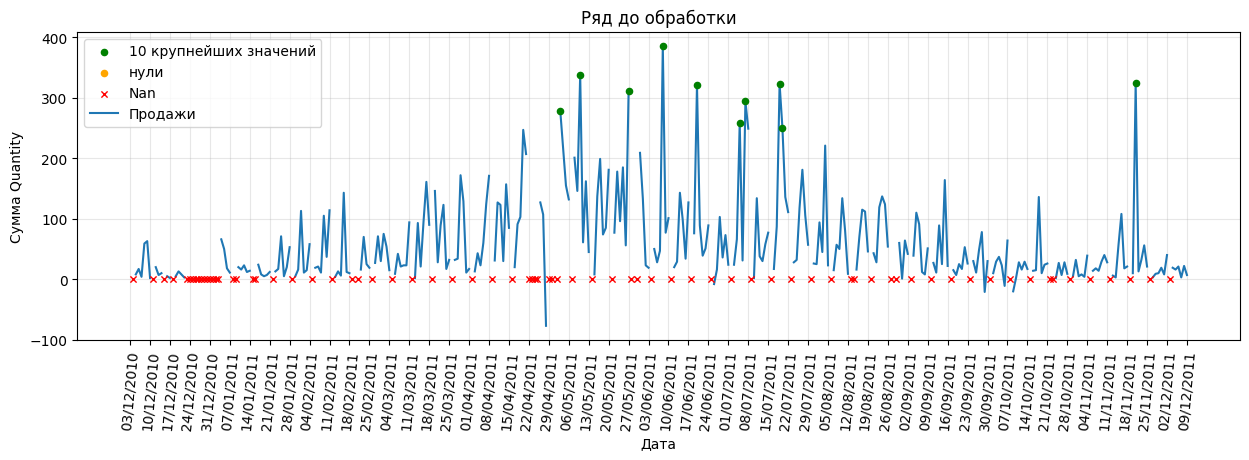

In [12]:
plot_ts_dummy(sales_daily, xticks_step=7, n_max=10, highlight_points=True, xticks_time=True)

In [13]:
def get_missing_periods(df):
    is_missing = df.Quantity.isna()
    groups = is_missing.ne(is_missing.shift()).cumsum()

    missing_periods = (
        df[is_missing]
        .groupby(groups[is_missing])
        .agg(
            start=('InvoiceDate', 'min'),
            end=('InvoiceDate', 'max'),
            days=('InvoiceDate', 'size')
        )
        .sort_values('days', ascending=False)
        .reset_index(drop=True)
    )
    return missing_periods

In [14]:
is_missing = sales_daily.Quantity.isna()
missing_daily = sales_daily[is_missing].copy()

missing_periods = get_missing_periods(sales_daily)

print('Периоды пропусков больше 1 дня:')
missing_periods[missing_periods.days >= 2]

Периоды пропусков больше 1 дня:


,start,end,days
0,2010-12-23,2011-01-03,12
1,2011-04-22,2011-04-25,4
2,2011-10-22,2011-10-23,2
3,2011-01-08,2011-01-09,2
4,2011-01-15,2011-01-16,2
5,2011-04-29,2011-04-30,2
6,2011-08-13,2011-08-14,2


> Первый период - это видимо рождественские праздники + новый год. Вероятно, тут действительно нули, и магазин не работал. 22-25 апреля могли быть пасхальные выходные. С остальными пропусками сложнее понять их причину. 

In [15]:
days = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'}
sales_daily['WeekDay'] = sales_daily.InvoiceDate.dt.dayofweek.map(days)
missing_daily['WeekDay'] = missing_daily.InvoiceDate.dt.dayofweek.map(days)

print('Пропуски по дням недели:')
display(missing_daily['WeekDay'].value_counts().sort_index().reset_index())

print('Записи по дням недели:')
display(sales_daily['WeekDay'][~is_missing].value_counts().sort_index().reset_index())

Пропуски по дням недели:


,WeekDay,count
0,Вс,7
1,Вт,1
2,Пн,7
3,Пт,4
4,Сб,53
5,Ср,2
6,Чт,2


Записи по дням недели:


,WeekDay,count
0,Вс,46
1,Вт,52
2,Пн,46
3,Пт,50
4,Ср,51
5,Чт,51


> Видим, что по субботам записей по этому товару не бывает вприницпе (наверное в этот день недели у магазина выходной), в остальные дни недели пропусков сильно меньше.

#### 2. Выявите потенциальные выбросы подходящим методом

> По правилу трех сигм посмотрим

In [16]:
find_outliers(sales_daily, method='sigma', need_print=True)

Границы: [-152.22, 273.99]
Потенциальных выбросов: 8


,InvoiceDate,Quantity,WeekDay
151,2011-05-03,279.0,Вт
216,2011-07-07,294.0,Чт
175,2011-05-27,312.0,Пт
199,2011-06-20,321.0,Пн
228,2011-07-19,323.0,Вт
353,2011-11-21,324.0,Пн
158,2011-05-10,338.0,Вт
187,2011-06-08,386.0,Ср


> Или по квантилям, выбросив пропуски

In [17]:
find_outliers(sales_daily, method='quantile', need_print=True)

Границы: [2.00, 271.50]
Потенциальных выбросов: 14


,InvoiceDate,Quantity,WeekDay
146,2011-04-28,-77.0,Чт
300,2011-09-29,-21.0,Чт
310,2011-10-09,-20.0,Вс
307,2011-10-06,-11.0,Чт
205,2011-06-26,-8.0,Вс
271,2011-08-31,1.0,Ср
151,2011-05-03,279.0,Вт
216,2011-07-07,294.0,Чт
175,2011-05-27,312.0,Пт
199,2011-06-20,321.0,Пн


#### 3. Визуализируйте ряд до обработки

> На графике выбросы определяю по квантилям

Периодов: 372

Без записей (Nan): 76
Нулевых сумм: 0
Отрицательных сумм: 5

Выбросов: 14


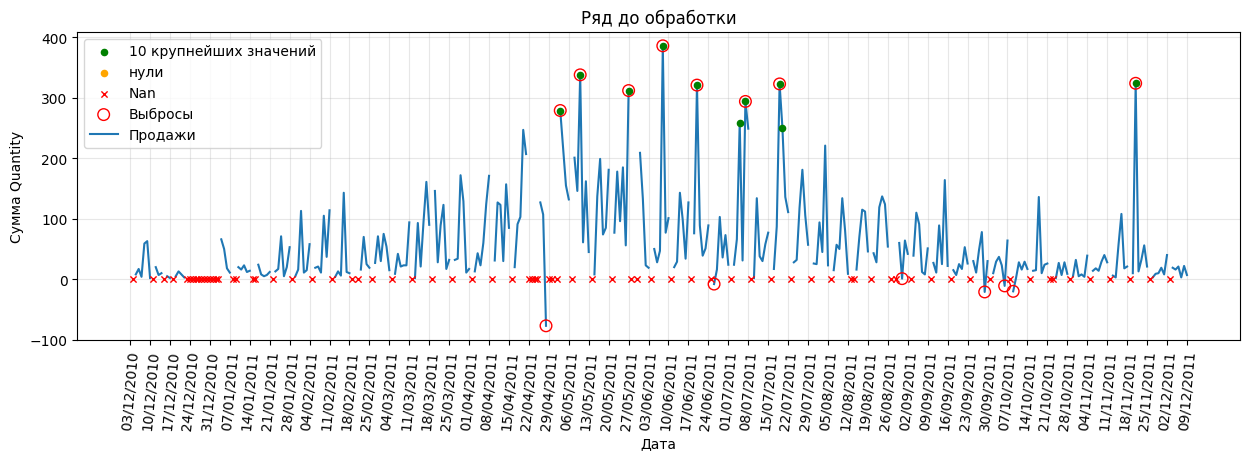

In [18]:
plot_ts_dummy(sales_daily, xticks_step=7, n_max=10, 
              highlight_points=True, draw_outliers=0.025, xticks_time=True)

#### 4. Если вы выполняете обработку пропусков или выбросов, обоснуйте выбранный способ и покажите результат.

> Выбросы пока оставим. Все кроме последнего пица и самого низкого значения вроде бы укладывается в общую картину ряда и не супер сильно выбивается из нее.

> Проверим, есть ли записи по другим товарам в субботу и зимние праздники `24.12.2010 - 04.01.2011`

In [19]:
import datetime

days = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'}
all_data['WeekDay'] = all_data.InvoiceDate.dt.dayofweek.map(days)
print(f"Записей в субботу по всему магазину: {len(all_data[all_data.WeekDay == 'Сб'])}")

all_winter_holidays = all_data[(all_data.InvoiceDate > datetime.datetime(year=2010, month=12, day=24)) & 
                               (all_data.InvoiceDate < datetime.datetime(year=2011, month=1, day=4))]
print(f"Записей в рождественские праздники по всему магазину: {len(all_winter_holidays)}")

Записей в субботу по всему магазину: 0
Записей в рождественские праздники по всему магазину: 0


> Давайте заменим на 0 те дни, когда записей нет по всем товарам - вероятно, в эти периоды магазин не работал впринципе, значит ничего не продавалось

In [20]:
active_days = pd.to_datetime(all_data.InvoiceDate).dt.normalize().unique()

mask_inactive = (
    sales_daily.Quantity.isna()
    & ~pd.to_datetime(sales_daily.InvoiceDate).dt.normalize().isin(active_days)
)

sales_daily.loc[mask_inactive, 'Quantity'] = 0

print(f'Заменено на 0 для: {mask_inactive.sum()} дней')

Заменено на 0 для: 69 дней


In [21]:
print(f'Осталось пропусков: {sales_daily.Quantity.isna().sum()}')

Осталось пропусков: 7


> Осталось 7 пропусков. Оставлять их не хотим, чтобы не заморачиваться потом с обработкой. Заполним медианой - она характеризует типичный уровень ряда. Так сможем получить ряд без пропусков, сохранив календарную сетку.

In [22]:
meadian_daily = np.median(sales_daily['Quantity'][~sales_daily['Quantity'].isna()])
sales_daily['Quantity'] = sales_daily.Quantity.fillna(meadian_daily)

Периодов: 372

Без записей (Nan): 0
Нулевых сумм: 69
Отрицательных сумм: 5

Выбросов: 15


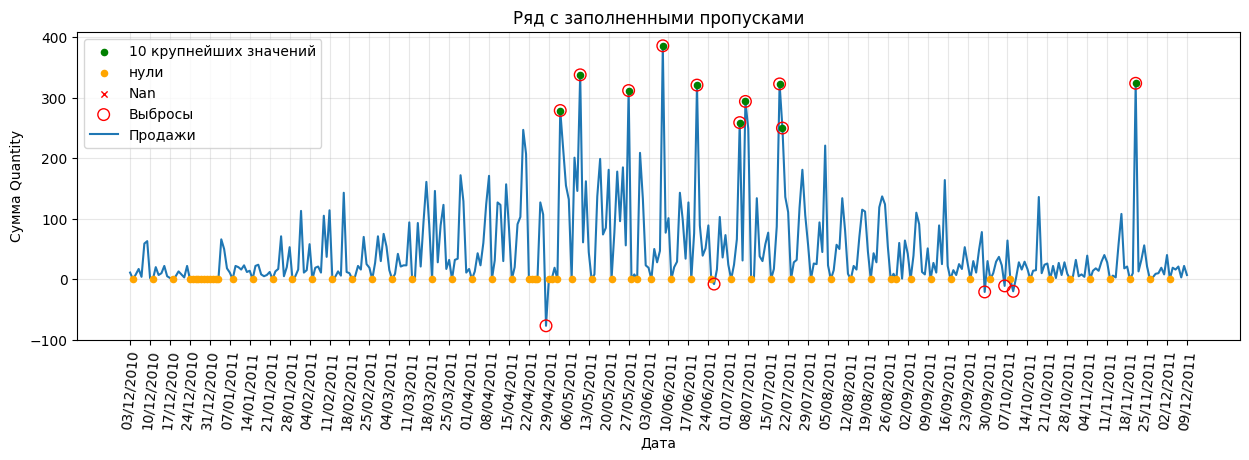

In [23]:
plot_ts_dummy(sales_daily, title='Ряд с заполненными пропусками', 
              xticks_step=7, n_max=10, 
              highlight_points=True, draw_outliers=0.025, xticks_time=True)

### б) Агрегация по неделям

#### 1. Проверьте временной ряд на пропуски и определите их количество и расположение.

In [24]:
sales_weekly.head(5)

,InvoiceDate,Quantity
0,2010-12-05,19.0
1,2010-12-12,165.0
2,2010-12-19,29.0
3,2010-12-26,24.0
4,2011-01-02,NaN


Периодов: 54

Без записей (Nan): 1
Нулевых сумм: 0
Отрицательных сумм: 0



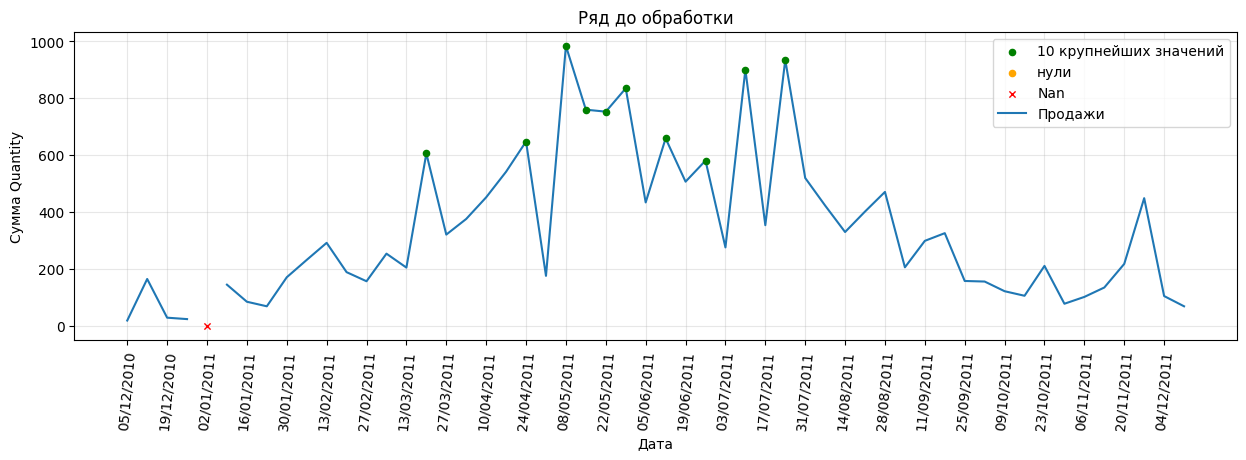

In [25]:
plot_ts_dummy(sales_weekly, xticks_step=2, n_max=10, highlight_points=True, xticks_time=True)

> Видим один пропуск - это он на те зимние праздники попал.

#### 2. Выявите потенциальные выбросы подходящим методом

> По правилу трех сигм посмотрим

In [26]:
find_outliers(sales_weekly, method='sigma', need_print=True)

Границы: [-420.72, 1100.80]
Потенциальных выбросов: 0


,InvoiceDate,Quantity


> Или по квантилям, выбросив пропуски

In [27]:
find_outliers(sales_weekly, method='quantile', need_print=True)

Границы: [25.50, 924.80]
Потенциальных выбросов: 4


,InvoiceDate,Quantity
0,2010-12-05,19.0
3,2010-12-26,24.0
33,2011-07-24,935.0
22,2011-05-08,984.0


#### 3. Визуализируйте ряд до обработки

> На графике выбросы определяю по квантилям

Периодов: 54

Без записей (Nan): 1
Нулевых сумм: 0
Отрицательных сумм: 0

Выбросов: 4


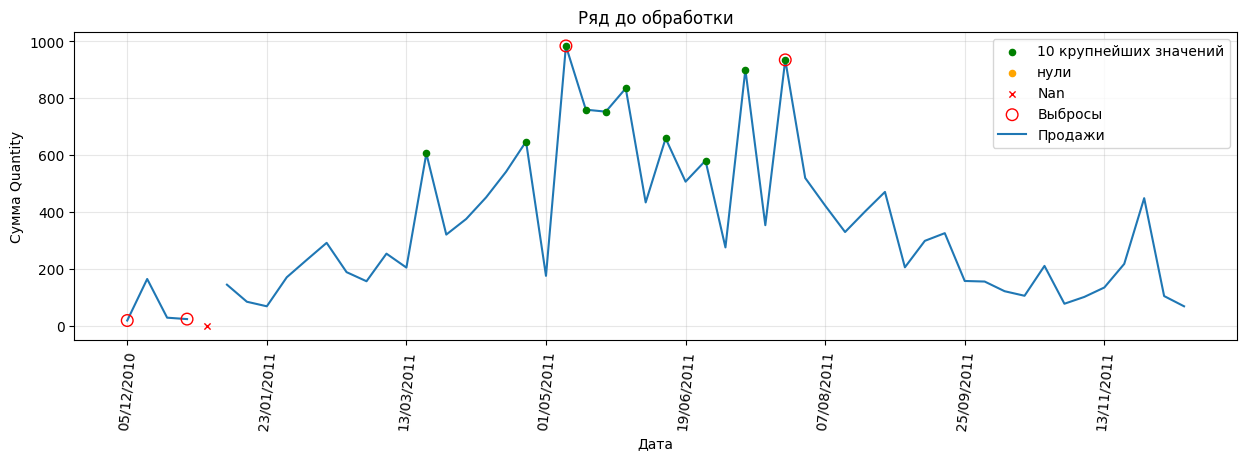

In [28]:
plot_ts_dummy(sales_weekly, xticks_step=7, n_max=10, 
              highlight_points=True, draw_outliers=0.025, xticks_time=True)

#### 4. Если вы выполняете обработку пропусков или выбросов, обоснуйте выбранный способ и покажите результат.

> Пики и нижние точки особо не выбиваются из общей кртины ряда, не будем работать с ними как с выбросами.

> Тут пропуск заменим на 0 - интерпретируем как отсутствие операций

In [29]:
sales_weekly.fillna(0, inplace=True)

### в) Агрегация по месяцам

#### 1. Проверьте временной ряд на пропуски и определите их количество и расположение.

In [30]:
sales_monthly.head(5)

,InvoiceDate,Quantity
0,2010-12-01,237
1,2011-01-01,486
2,2011-02-01,925
3,2011-03-01,1661
4,2011-04-01,1829


Периодов: 13

Без записей (Nan): 0
Нулевых сумм: 0
Отрицательных сумм: 0



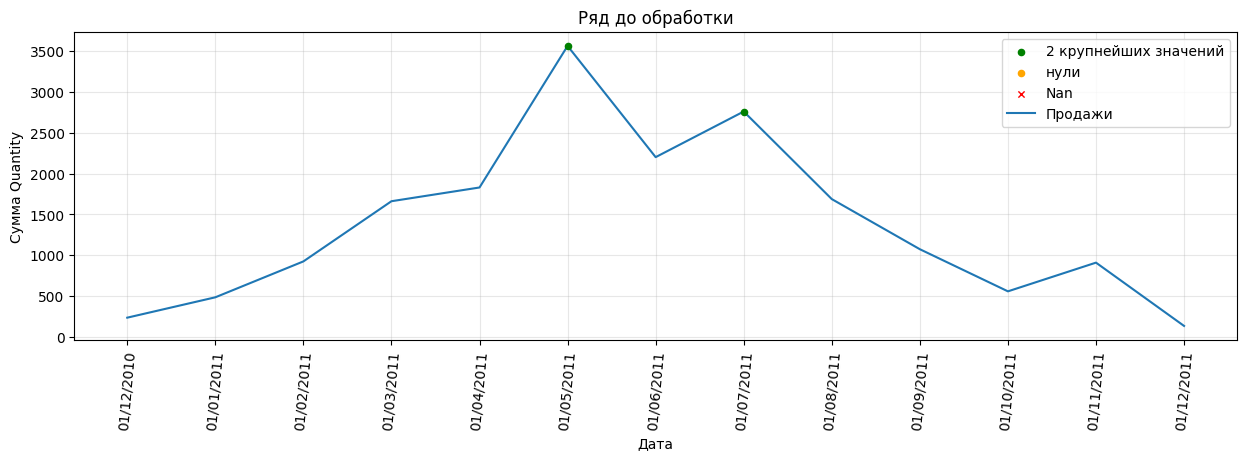

In [31]:
plot_ts_dummy(sales_monthly, xticks_step=1, n_max=2, highlight_points=True, xticks_time=True)

#### 2. Выявите потенциальные выбросы подходящим методом

> По правилу трех сигм посмотрим

In [32]:
find_outliers(sales_monthly, method='sigma', need_print=True)

Границы: [-1681.28, 4453.90]
Потенциальных выбросов: 0


,InvoiceDate,Quantity


> Или по квантилям, выбросив пропуски

In [33]:
find_outliers(sales_monthly, method='quantile', need_print=True)

Границы: [166.30, 3319.40]
Потенциальных выбросов: 2


,InvoiceDate,Quantity
12,2011-12-01,136
5,2011-05-01,3560


#### 3. Визуализируйте ряд до обработки

> На графике выбросы определяю по квантилям

Периодов: 13

Без записей (Nan): 0
Нулевых сумм: 0
Отрицательных сумм: 0

Выбросов: 2


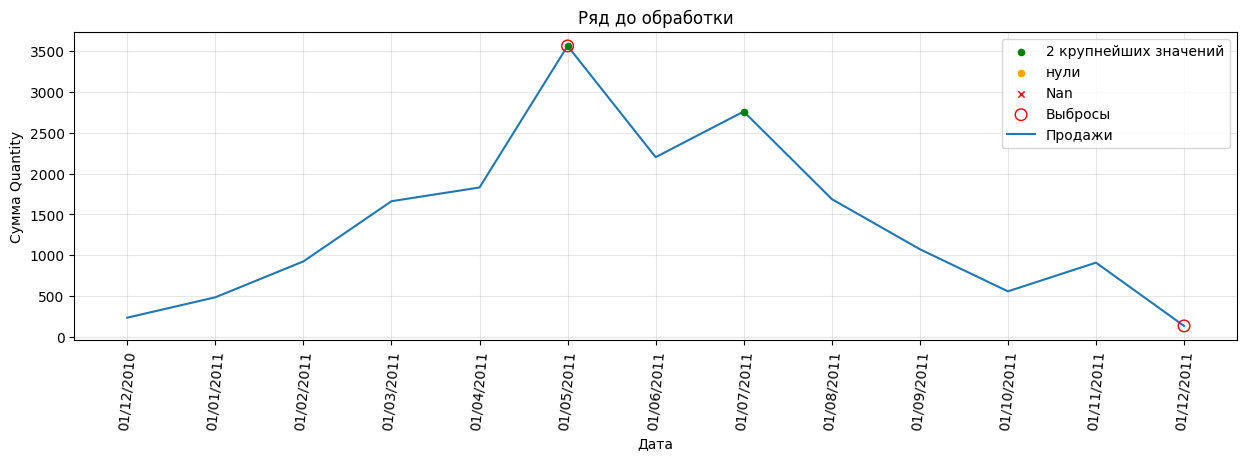

In [34]:
plot_ts_dummy(sales_monthly, xticks_step=1, n_max=2, 
              highlight_points=True, draw_outliers=0.025, xticks_time=True)

#### 4. Если вы выполняете обработку пропусков или выбросов, обоснуйте выбранный способ и покажите результат.

> По месяцам пропусков нет, пик и нижняя точка в конце выглядят достаточно естественно, поэтому оставляем как есть.

## Шаг 3. Проведите визуальный и описательный анализ

> Ренее я заполняла пропуски для агрегаций независимо и не пересчитывала, например, недельную агрегацию после обработки дневной. То есть теперь каждая частота анализируется после собственной предобработки.

### а) Агрегация по дням

#### 1. Постройте график временного ряда. 

Периодов: 372

Без записей (Nan): 0
Нулевых сумм: 69
Отрицательных сумм: 5



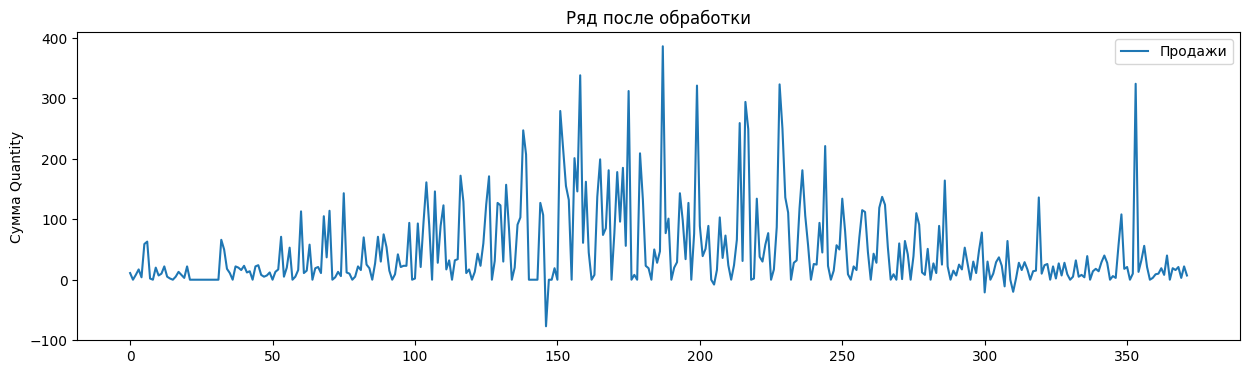

In [35]:
plot_ts_dummy(sales_daily, title='Ряд после обработки')

> На графике видны периоды разного уровня продаж и отдельные высокие пики.

#### 2. Рассчитайте основные описательные статистики и дополнительные характеристики, которые считаете полезными для анализа продаж. 

In [36]:
def describe_sales(df):
    ordered = df.sort_values('InvoiceDate')
    y = ordered.Quantity
    observed = y.dropna()
    mean = observed.mean()
    std = observed.std()

    is_zero = y.eq(0)
    groups = is_zero.ne(is_zero.shift(fill_value=False)).cumsum()
    zero_run = is_zero.groupby(groups).sum().max() if len(y) else 0

    return pd.Series({
        'Периодов всего': len(y),
        'Известных значений': observed.count(),
        'NaN': y.isna().sum(),
        'Доля NaN, %': y.isna().mean() * 100,
        'Среднее, шт.': mean,
        'Медиана, шт.': observed.median(),
        'Стандартное отклонение, шт.': std,
        'Дисперсия, шт.²': observed.var(),
        'Минимум, шт.': observed.min(),
        'Квантиль 5%, шт.': observed.quantile(0.05),
        'Квантиль 25%, шт.': observed.quantile(0.25),
        'Квантиль 75%, шт.': observed.quantile(0.75),
        'Квантиль 95%, шт.': observed.quantile(0.95),
        'Максимум, шт.': observed.max(),
        'Нулевых значений': observed.eq(0).sum(),
        'Доля нулевых значений, %': observed.eq(0).mean() * 100,
        'Отрицательных значений': observed.lt(0).sum(),
        'Доля отрицательных значений, %': observed.lt(0).mean() * 100,
        'Коэффициент вариации, %': std / mean * 100 if mean > 0 else np.nan,
        'Максимум нулей подряд': zero_run
    }, name='Значение')

In [37]:
daily_stats = describe_sales(sales_daily)
daily_stats.round(2).to_frame()

,Значение
Периодов всего,372.00
Известных значений,372.00
NaN,0.00
"Доля NaN, %",0.00
"Среднее, шт.",48.86
"Медиана, шт.",22.00
"Стандартное отклонение, шт.",67.71
"Дисперсия, шт.²",4585.19
"Минимум, шт.",-77.00
"Квантиль 5%, шт.",0.00


#### 3. Исследуйте изменение уровня и разброса значений во времени. 

In [38]:
def plot_rolling_stats(df, window, title='Скользящие статистики',
                       ylabel='Количество с учетом возвратов', label='Сумма Quantity'):
    ordered = df.sort_values('InvoiceDate')
    y = ordered.set_index('InvoiceDate').Quantity
    rolling = y.rolling(window=window, min_periods=window)
    result = pd.DataFrame({
        'mean': rolling.mean(),
        'std': rolling.std()
    })

    _, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    axes[0].plot(y.index, y, alpha=0.35, linewidth=1, label=label)
    axes[0].plot(result.index, result['mean'], color='red', linewidth=2,
                 label=f'Среднее за {window} периодов')
    axes[0].set_title(f'уровень')
    axes[0].set_ylabel(ylabel)

    axes[1].plot(result.index, result['std'], color='purple',
                 label=f'Стандартное отклонение за {window} периодов')
    axes[1].set_title(f'разброс')
    axes[1].set_ylabel('Стандартное отклонение')
    axes[1].set_xlabel('Дата')

    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)
    plt.suptitle(f'{title}, окно {window}', fontsize=15)
    plt.tight_layout()
    plt.show()
    return result

> Рассмотрим изменения с разными окнами периодов.

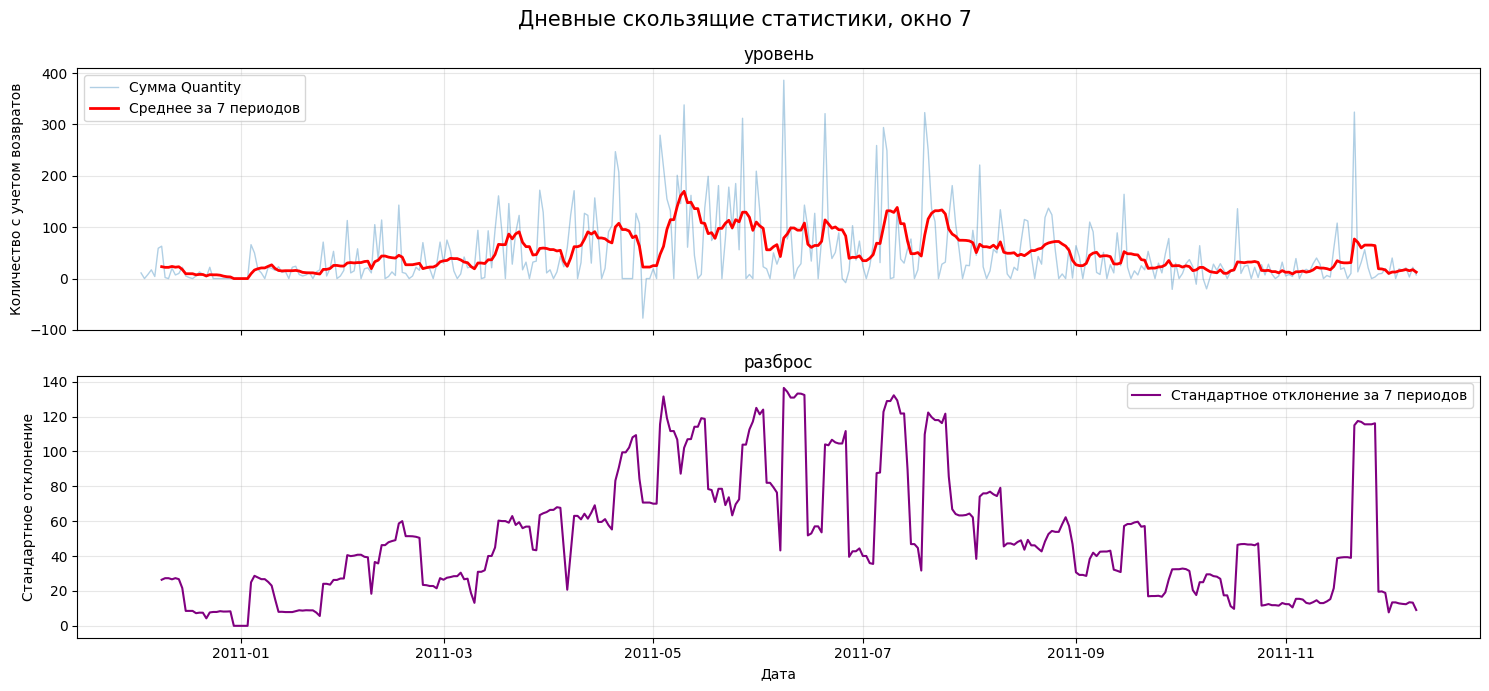

In [39]:
rolling_daily = plot_rolling_stats(sales_daily, window=7,
                                   title=f'Дневные скользящие статистики')

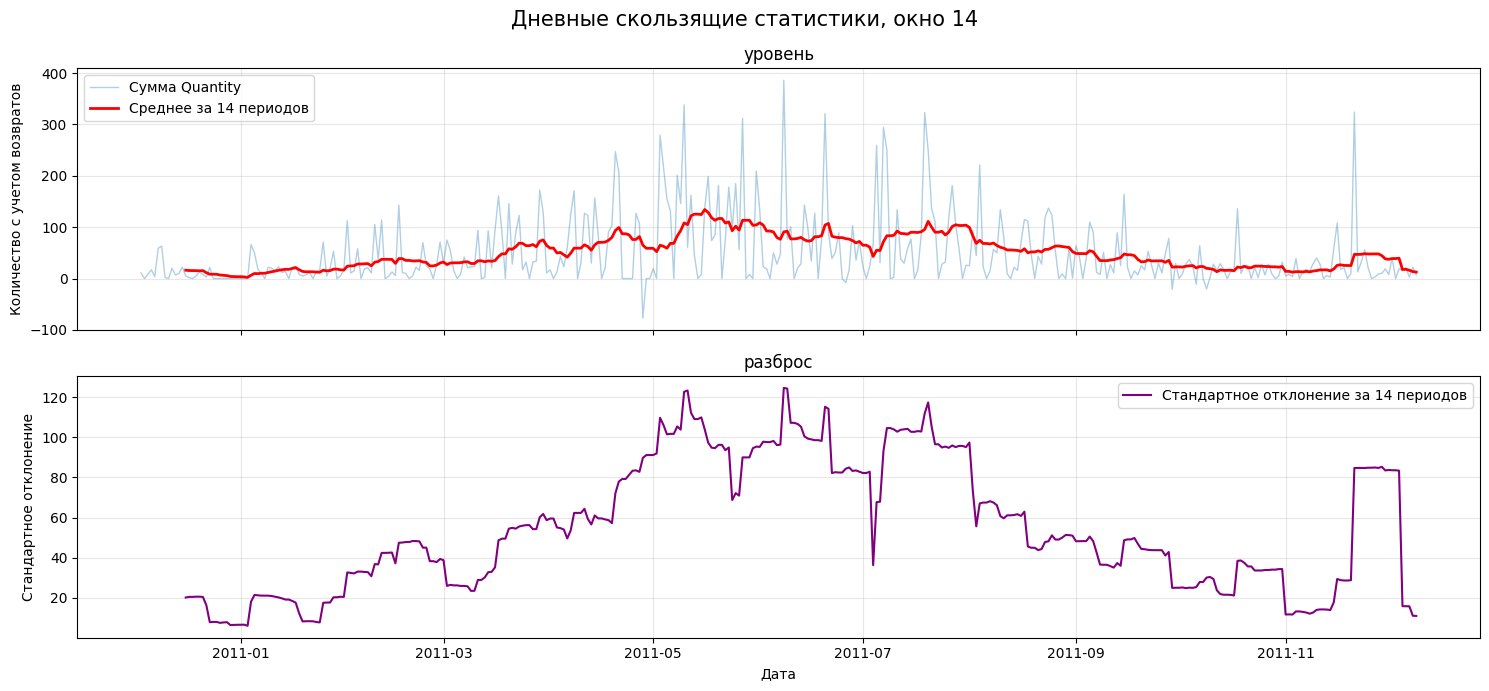

In [40]:
rolling_daily = plot_rolling_stats(sales_daily, window=14,
                                   title=f'Дневные скользящие статистики')

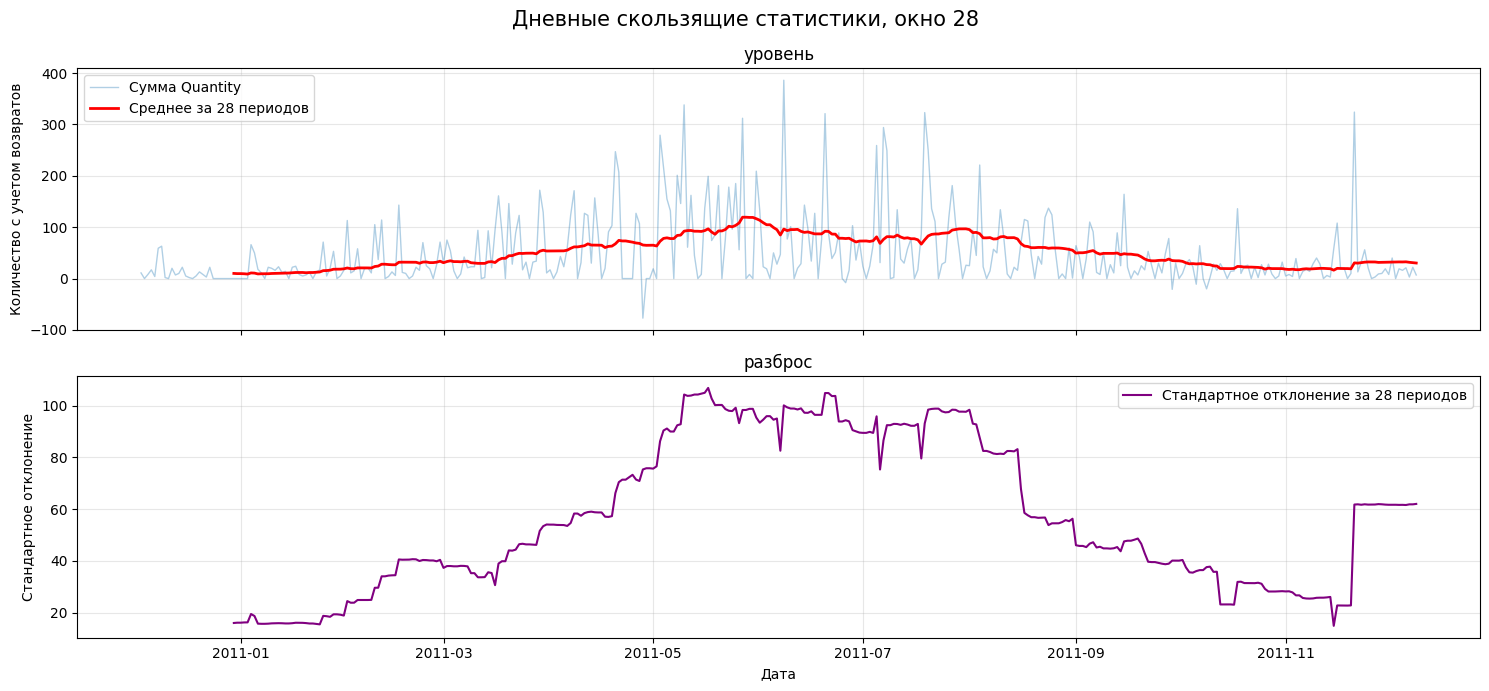

In [41]:
rolling_daily = plot_rolling_stats(sales_daily, window=28,
                                   title=f'Дневные скользящие статистики')

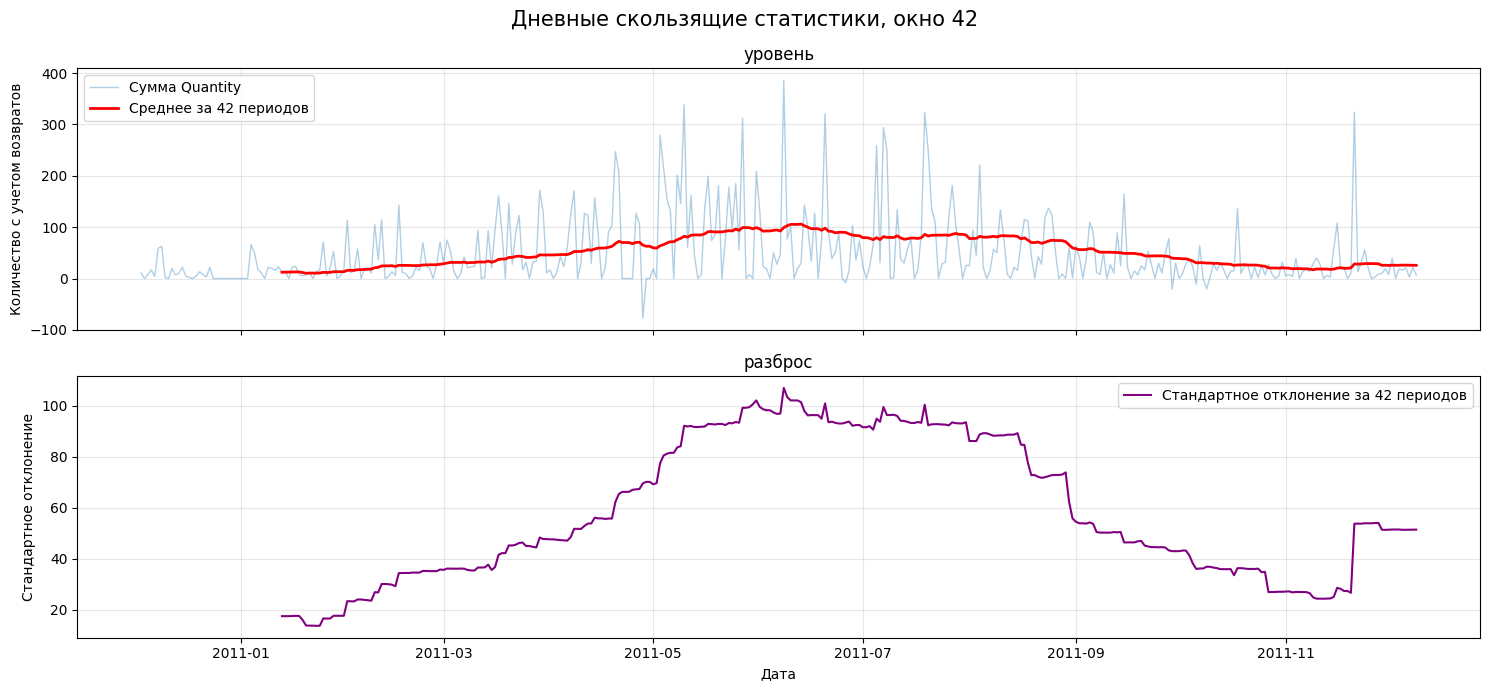

In [42]:
rolling_daily = plot_rolling_stats(sales_daily, window=42,
                                   title=f'Дневные скользящие статистики')

> Окно смотрит назад и включает текущий день.
>
> Скользящее среднее показывает, что уровень продаж меняется во времени (лучше видно на последних 2 графиках): в начале наблюдения он относительно низкий, а достигает наиболее высоких значений в мае-июне.
>
> Разброс тоже неоднородный. Скользящее стандартное отклонение увеличивается в середине наблюдений, и есть пик к концу наблюдений в ноябре. Можно сказать, что разброс выше тогда, когда больше дневные продажи.
>
> Меньшие окна (7 и 14 дней) лучше показывают краткосрочные изменения, но сильнее реагируют на отдельные пики. Более широкие окна (28 и 42 дня) дают более гладкую картину общего изменения уровня и разброса, но реагируют на изменения с запаздыванием.
>
> Судя по этим графикам, есть признаки того, что ряд нестационарен, но это позже проверим статистическими тестами.

#### 4. При необходимости используйте дополнительные графики для выявления закономерностей. 

In [43]:
def plot_extra_distribution(df, title='Распределение продаж', bins=30):
    y = df.Quantity.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].hist(y, bins=bins, edgecolor='white', alpha=0.8)
    axes[0].axvline(y.mean(), color='red', linestyle='--', label='Среднее')
    axes[0].axvline(y.median(), color='green', linestyle='--', label='Медиана')
    axes[0].set_title('Гистограмма')
    axes[0].set_xlabel('Сумма Quantity, шт.')
    axes[0].set_ylabel('Число периодов')
    axes[0].legend()

    axes[1].boxplot(y, vert=False)
    axes[1].set_title('Boxplot: медиана, квартили и значения за усами')
    axes[1].set_xlabel('Сумма Quantity, шт.')
    axes[1].set_ylabel('Quantity')

    for ax in axes:
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

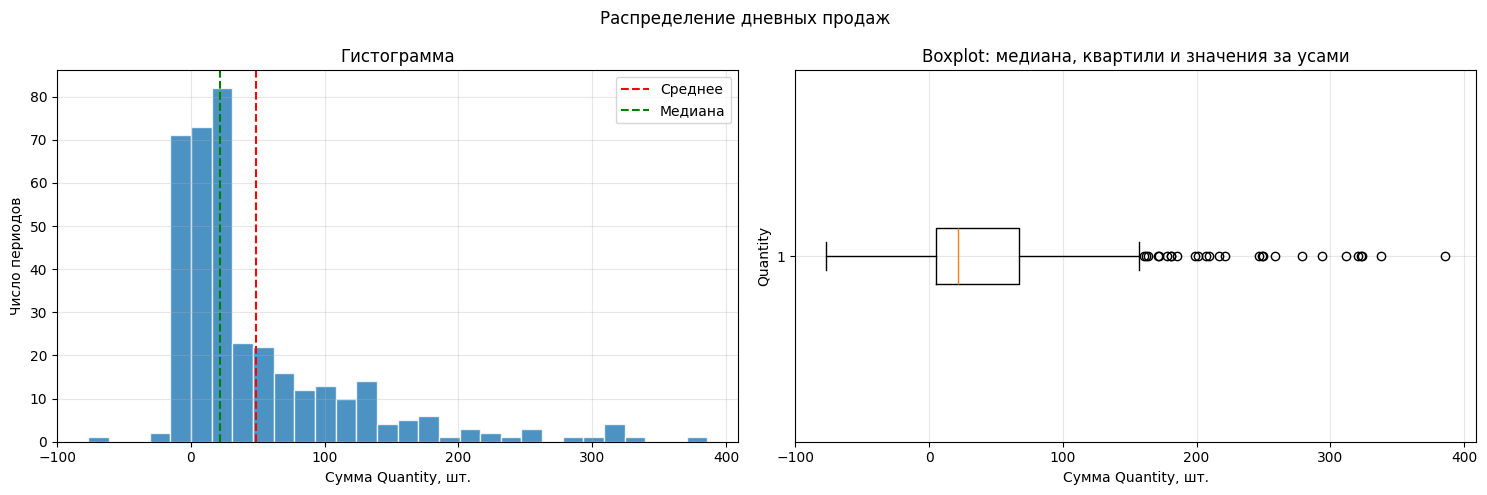

In [44]:
plot_extra_distribution(sales_daily, title=f'Распределение дневных продаж')

> На гистограмме длинный правый хвост, поэтому среднее значительно больше медианы. Boxplot показывает высокие значения за правым усом, эти отдельные точки - потенциальные выросы.

### б) Агрегация по неделям

#### 1. Постройте график временного ряда. 

Периодов: 54

Без записей (Nan): 0
Нулевых сумм: 1
Отрицательных сумм: 0



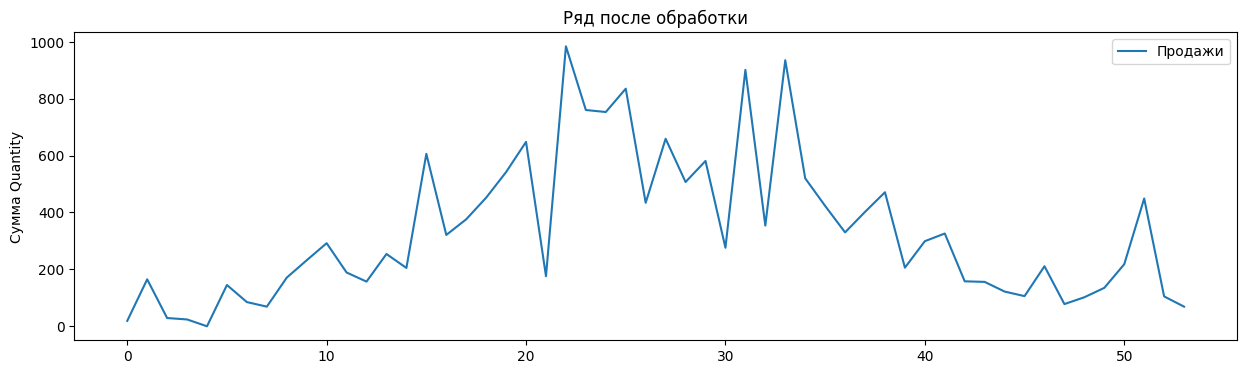

In [45]:
plot_ts_dummy(sales_weekly, title='Ряд после обработки')

#### 2. Рассчитайте основные описательные статистики и дополнительные характеристики, которые считаете полезными для анализа продаж. 

In [46]:
daily_stats = describe_sales(sales_weekly)
daily_stats.round(2).to_frame()

,Значение
Периодов всего,54.00
Известных значений,54.00
NaN,0.00
"Доля NaN, %",0.00
"Среднее, шт.",333.74
"Медиана, шт.",265.00
"Стандартное отклонение, шт.",255.41
"Дисперсия, шт.²",65233.71
"Минимум, шт.",0.00
"Квантиль 5%, шт.",27.25


> Недельная агрегация сглаживает часть дневных колебаний (коэффициент вариации снижается со ~140 до 76), но относительный разброс недельных продаж все еще значительный.

#### 3. Исследуйте изменение уровня и разброса значений во времени. 

> Рассмотрим изменения с разными окнами периодов.

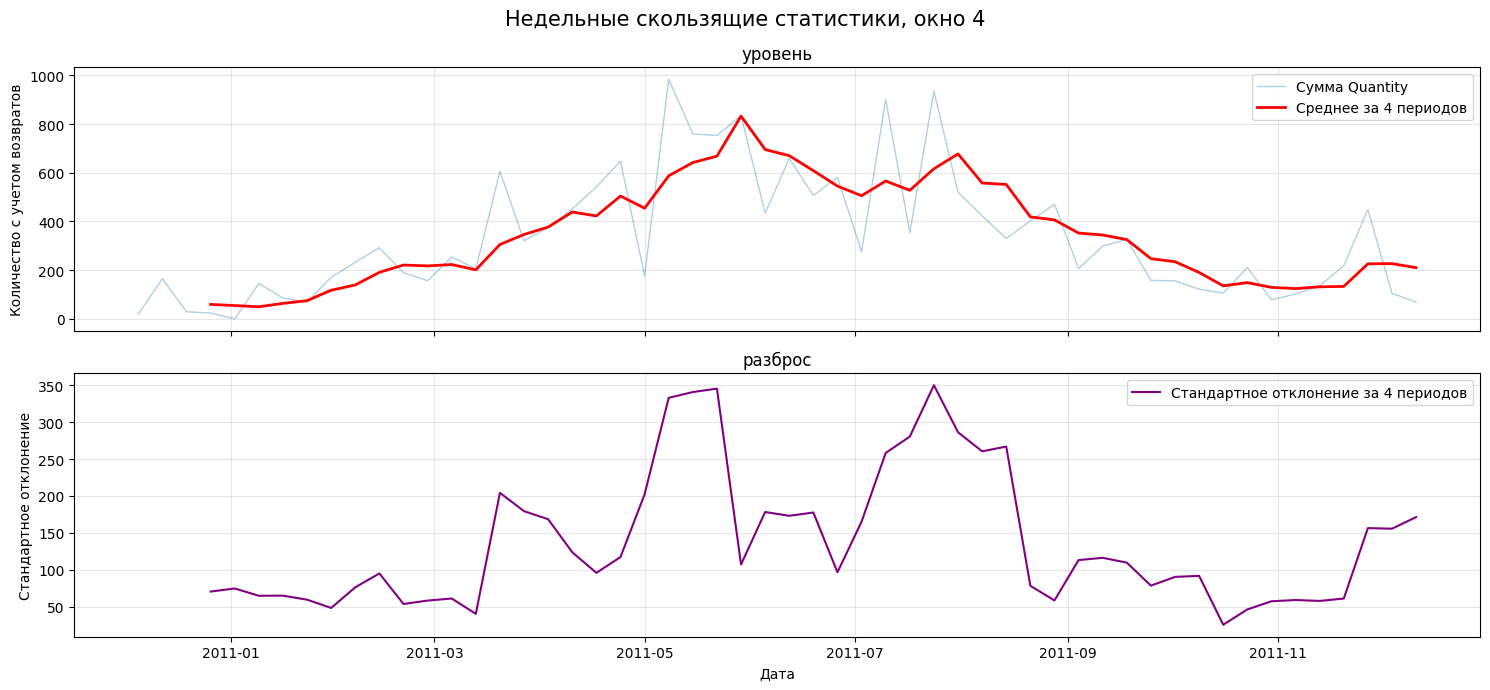

In [47]:
rolling_daily = plot_rolling_stats(sales_weekly, window=4,
                                   title=f'Недельные скользящие статистики')

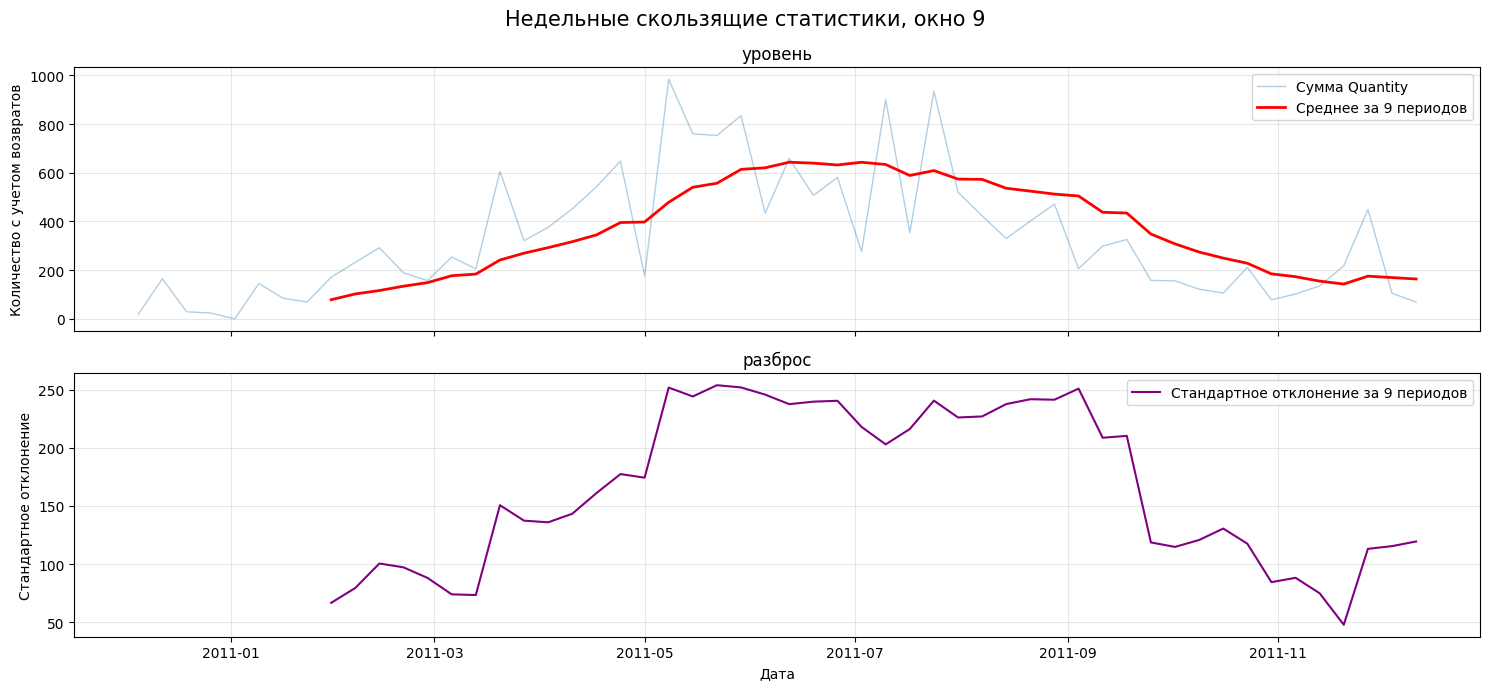

In [48]:
rolling_daily = plot_rolling_stats(sales_weekly, window=9,
                                   title=f'Недельные скользящие статистики')

> Скользящее среднее показывает рост недельных продаж в ~июне (то же мы наблюдали в дневной агрегации). Тенденции графика разборса тоже похожи на то, что мы уже видели в агрегации по дням, но здесь более гладко за счет больших периодов.
> 
> Окно 4 недели лучше отражает краткосрочные изменения и отдельные пики. Окно 9 недель сильнее сглаживает колебания и яснее показывает общую динамику, но реагирует с запаздыванием. 

#### 4. При необходимости используйте дополнительные графики для выявления закономерностей. 

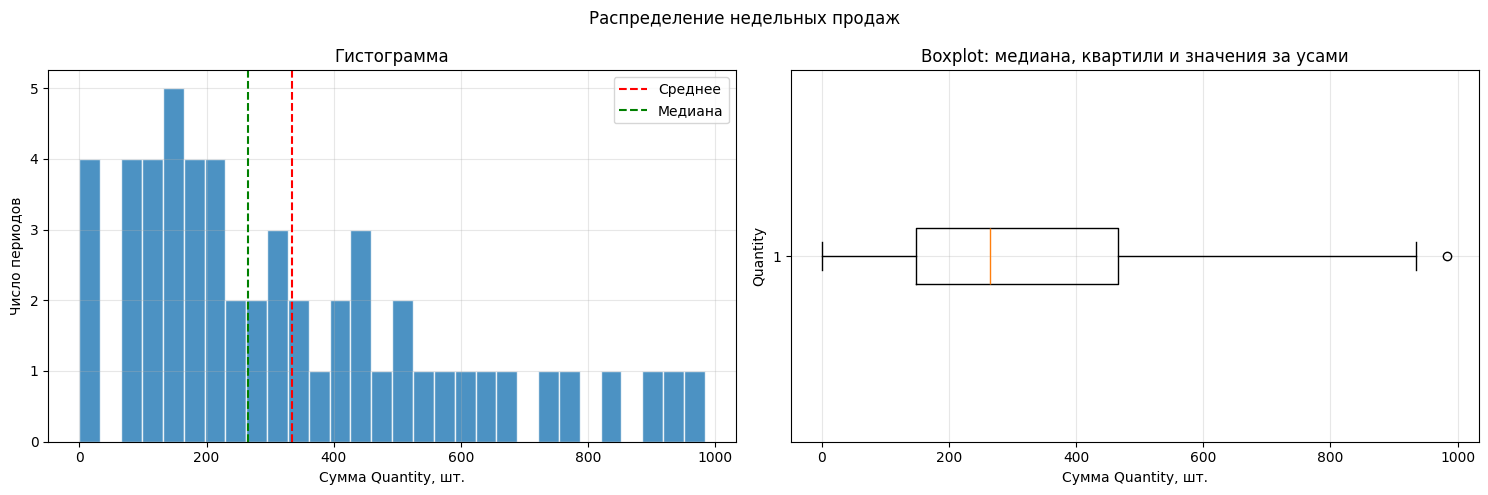

In [49]:
plot_extra_distribution(sales_weekly, title=f'Распределение недельных продаж')

> Распределение недельных продаж тоже имеет правый хвост, и большие суммы встречаются реже меньших относительно небольших.
>
> На boxplot отдельно выделяется одна точка с большими продажами.

### в) Агрегация по месяцам

#### 1. Постройте график временного ряда. 

Периодов: 13

Без записей (Nan): 0
Нулевых сумм: 0
Отрицательных сумм: 0



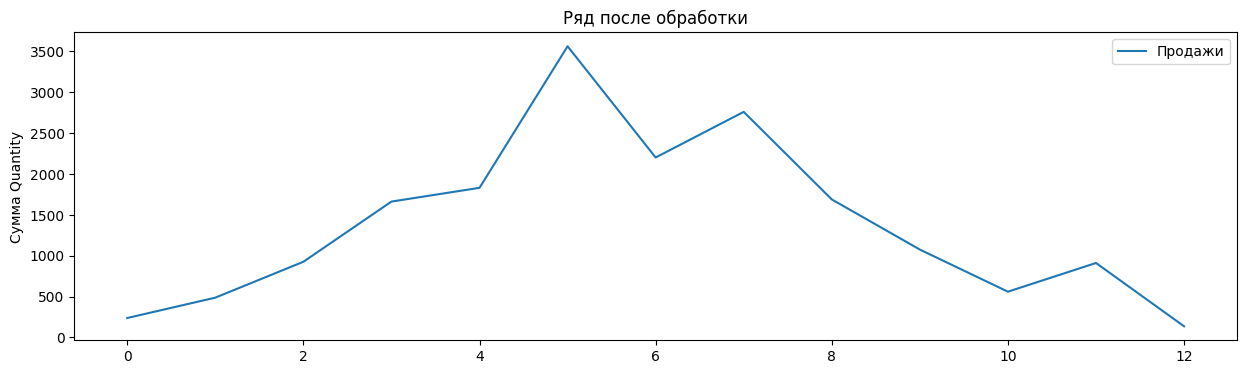

In [50]:
plot_ts_dummy(sales_monthly, title='Ряд после обработки')

#### 2. Рассчитайте основные описательные статистики и дополнительные характеристики, которые считаете полезными для анализа продаж. 

In [51]:
daily_stats = describe_sales(sales_monthly)
daily_stats.round(2).to_frame()

,Значение
Периодов всего,13.00
Известных значений,13.00
NaN,0.00
"Доля NaN, %",0.00
"Среднее, шт.",1386.31
"Медиана, шт.",1074.00
"Стандартное отклонение, шт.",1022.53
"Дисперсия, шт.²",1045566.73
"Минимум, шт.",136.00
"Квантиль 5%, шт.",196.60


> Переход от недель к месяцам лишь немного уменьшает относительный разброс. Это указывает на то, что неравномерность связана не только с отдельными дневными пиками, но и с различиями между длительными периодами.

#### 3. Исследуйте изменение уровня и разброса значений во времени. 

> Рассмотрим изменения с разными окнами периодов.

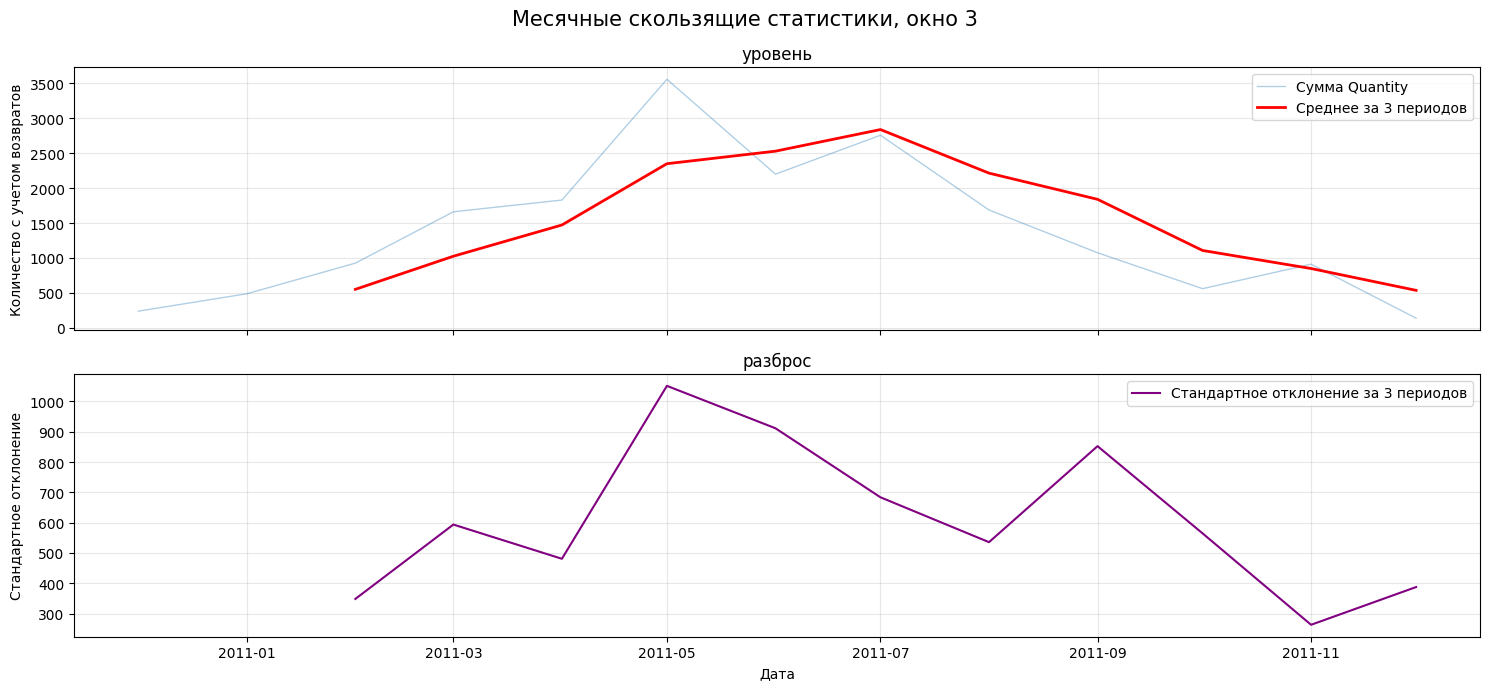

In [52]:
rolling_daily = plot_rolling_stats(sales_monthly, window=3,
                                   title=f'Месячные скользящие статистики')

> Скользящее среднее за три месяца растет до июля, после чего снижается. Его максимум наступает позже максимума исходного ряда, поскольку окно включает предыдущие месяцы.
>
> Месячная агрегация может скрывать дневные аномалии, а по 13 значениям сложно судить о форме распределения.

## Шаг 4. Выполните декомпозицию временного ряда

### а) Агрегация по дням

#### 1. Выберите подходящий метод декомпозиции. 

> Возьмем главным STL, как на семинаре. Он раскладывает ряд в сумму тренда, сезонности и остатка и может учитывать меняющуюся во времени сезонность. Аддитивное разложение подходит для ряда с нулями и отрицательными значениями. При работе с произведением возникнут сложности.
>
> Проверим сначала недельный цикл (`period=7`). `robust=True` уменьшит влияние отдельных пиков на компоненты. Используем дневной ряд после заполнения пропусков из шага 2.

#### 2. Разложите временной ряд на компоненты, предусмотренные выбранным методом. 

In [53]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.signal import periodogram, find_peaks

In [54]:
def decompose_sales_stl(df, period, seasonal, trend=None, title='Декомпозиция STL'):
    y = df.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']

    result = STL(y, period=period, seasonal=seasonal, trend=trend, robust=True).fit()
    fig = result.plot()
    fig.set_size_inches(12, 6)
    labels = ['Продажи', 'Тренд', 'Сезонность', 'Остаток']
    for ax, label in zip(fig.axes, labels):
        ax.set_title('')
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
    fig.axes[-1].set_xlabel('Дата')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return result

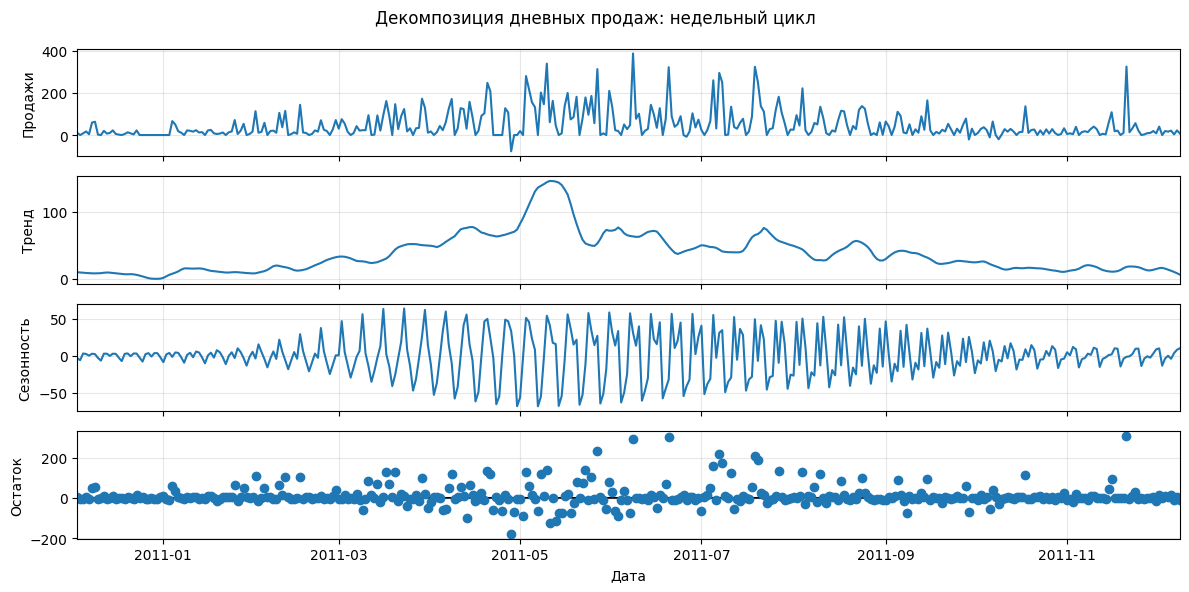

In [55]:
stl_daily = decompose_sales_stl(sales_daily, period=7, seasonal=15,
                                title='Декомпозиция дневных продаж: недельный цикл')

> Тренд слишком сильно колеблется. Похоже, что рисунок сезонности повторяется по циклу, но с разной амплитудой. Остаток не похож на нормальный шум. Постараюсь подобрать параметры, чтобы разделение получилось лучше.

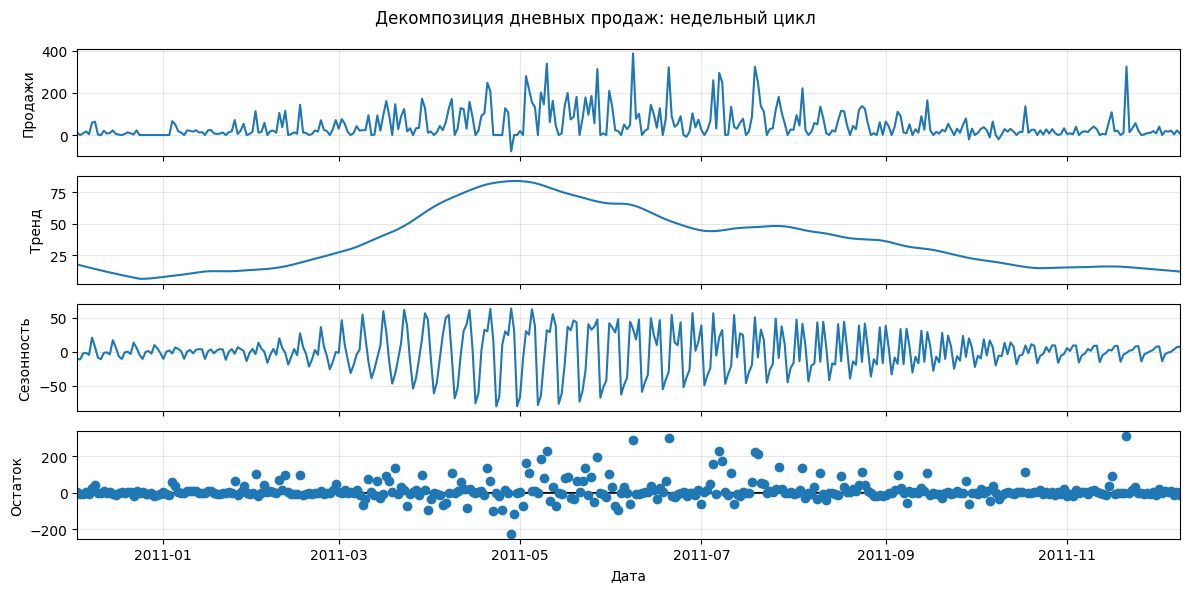

In [56]:
stl_daily = decompose_sales_stl(sales_daily, period=7, seasonal=13, trend=43,
                            title='Декомпозиция дневных продаж: недельный цикл')

> Теперь тренд достаточно плавный и отражает изменения за несколько недель.
>
> Единственного правильного разложения нет. Изменение амплитуды сезонности допустимо. В остатке все еще есть крупные пики, от них не удалось избавиться. Возможно, при обработке данных стоило обработать большие выбросы.

> Еще попробуем график через `seasonal_decompose`. Он хорошо работает, если сезонный рисунок практически не меняется.

In [57]:
def decompose_sales_classical(df, period, filt=None,
                              title='Классическая декомпозиция', plot=True):
    y = df.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']
    result = seasonal_decompose(y, model='additive', period=period, filt=filt)

    if plot:
        fig = result.plot()
        fig.set_size_inches(12, 7)
        labels = ['Продажи', 'Тренд', 'Сезонность', 'Остаток']
        for ax, label in zip(fig.axes, labels):
            ax.set_title('')
            ax.set_ylabel(f'{label}')
            ax.grid(alpha=0.3)
        fig.axes[-1].set_xlabel('Дата')
        fig.suptitle(title)
        fig.tight_layout(rect=(0, 0, 1, 0.96))
        plt.show()
    return result

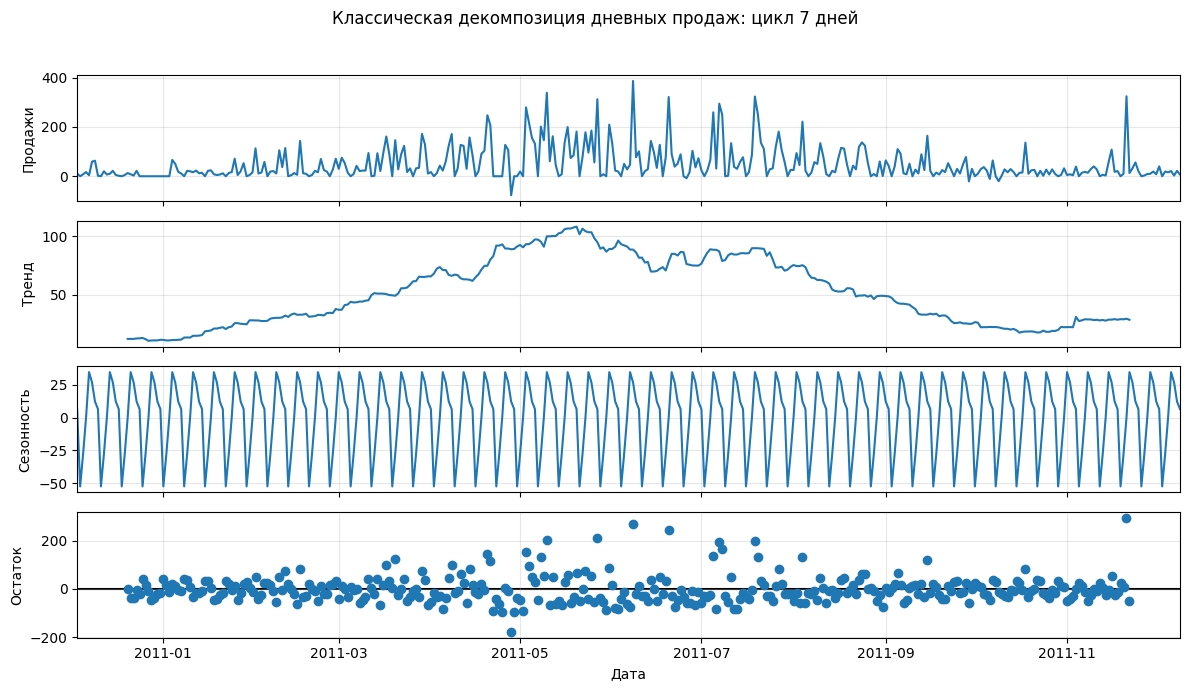

In [58]:
classical_daily = decompose_sales_classical(
    sales_daily, period=7, filt=np.ones(35) / 35,
    title='Классическая декомпозиция дневных продаж: цикл 7 дней'
)

> `filt=np.ones(35)/35` выделяет тренд средним за пять полных недель. Без filt здесь использовалось бы окно 7 дней, и тренд сильнее реагировал бы на краткосрочные изменения.
>
> Тут тренд получился более неустойчивым, в сезонности тоже видим повторяющийся паттерн

> Для подневной агрегации посмотрим и MSTL - расширение STL на несколько сезонных компонентов. На днях мы можем отследить цикты по неделям и месяцам, например.

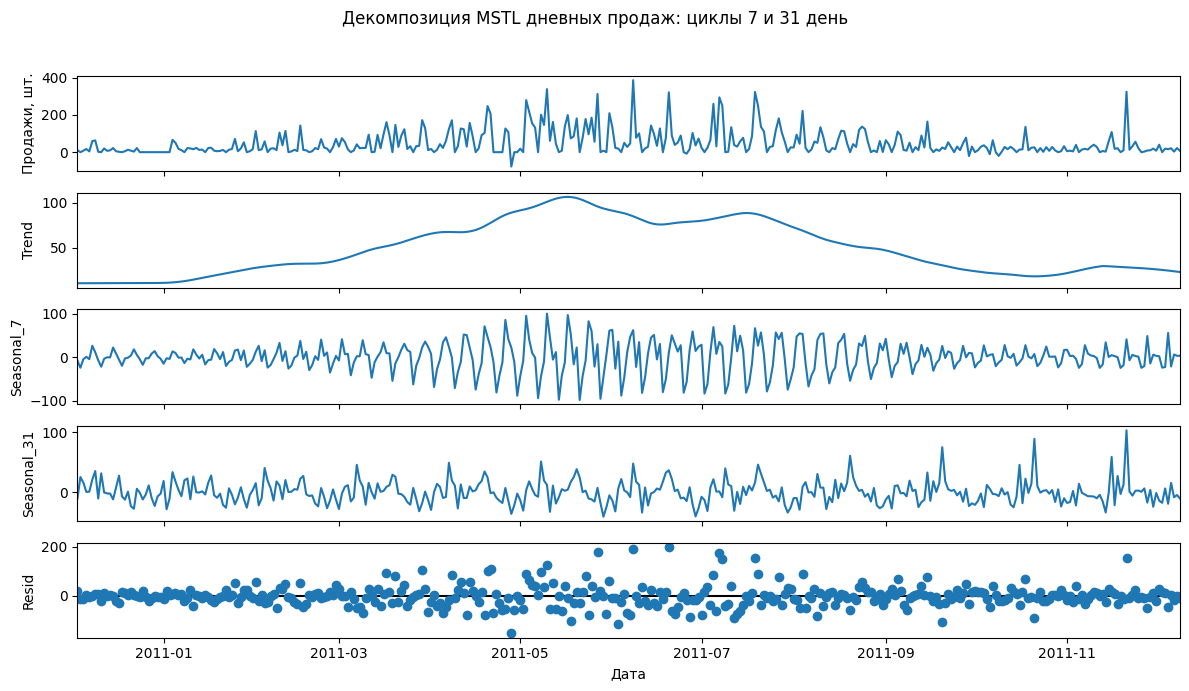

In [59]:
def plot_decomposition(result, title, figsize=(12, 6)):
    fig = result.plot()
    fig.set_size_inches(*figsize)
    fig.suptitle(title)
    fig.axes[0].set_title('')
    fig.axes[0].set_ylabel('Продажи, шт.')
    fig.axes[-1].set_xlabel('Дата')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


mstl = MSTL(
    sales_daily.set_index('InvoiceDate')["Quantity"],
    periods=[7, 31],
)

result = mstl.fit()
plot_decomposition(result, 'Декомпозиция MSTL дневных продаж: циклы 7 и 31 день',
                   figsize=(12, 7))

> MSTL показывает подъем тренда к маю, небольшой повторный подъем летом, а дальше спад. Недельные колебания имеют повторяющийся паттернсильнее весной и летом, когда выше уровень продаж. Компонента с периодом 31 день рассматривается как гипотеза о наличии такого цикла, в ней сложный паттерн и визуально не могу сказать, одинаковый ли рисунок повторяется (проверим позже). Остаток остается большим.

#### 3. Проанализируйте тренд, сезонную и остаточную составляющие, если они выделяются используемым методом.

> Тренд. Уровень продаж растет к маю, в июле есть локальный подъем, затем в целом снижается. Ноябрьский всплеск не превратился в устойчивый рост тренда.
>
> Сезонность. Выделяется недельный рисунок с меняющейся амплитудой. Колебания сильнее весной и летом, когда выше общий уровень продаж.
>
> Остаток. Сохраняются крупные положительные пики и отдельные отрицательные отклонения, особенно весной и летом. Значит, тренд и недельный цикл объясняют только часть колебаний.

#### 4. Сделайте вывод о наличии или отсутствии выраженной сезонности.

Если сезонность предполагается, укажите ее предполагаемый период и обоснуйте вывод результатами 
анализа. 

> Проверим сезонность на дневном ряду с помощью ACF и периодограммы. Для первичного поиска уберем плавный тренд LOWESS.
>
> `max_lag` ограничивает ACF, `max_period` - диапазон периодов на периодограмме.

In [60]:
def check_seasonality(result, periods=(7,), max_lag=100, max_period=60,
                      top_n=5, trend_frac=0.4):
    y = np.asarray(result.observed, dtype=float)
    residual = np.asarray(result.resid, dtype=float)
    periods = sorted(set(periods))
    if not periods or any(p < 2 or int(p) != p for p in periods):
        raise ValueError('Периоды должны быть целыми числами не меньше 2')
    periods = [int(p) for p in periods]
    lags = min(max_lag, len(y) - 1)
    period_limit = min(max_period, len(y) // 2)

    trend = lowess(y, np.arange(len(y)), frac=trend_frac, it=3, return_sorted=False)
    series = {'Без плавного тренда': y - trend, 'Остаток STL': residual}
    selected_lags = sorted({p * k for p in periods for k in range(1, 5) if p * k <= lags})
    acf_values, peaks = {}, []
    fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex='row', sharey='row')
    colors = plt.cm.tab10((np.arange(len(periods)) + 1) % 10)

    for col, (name, values) in enumerate(series.items()):
        plot_acf(values, lags=lags, zero=False, ax=axes[0, col], title=f'ACF: {name.lower()}')
        acf_values[name] = acf(values, nlags=lags)[selected_lags]

        frequency, power = periodogram(values, fs=1, window='hann', detrend='constant')
        mask = (frequency >= 1 / period_limit) & (frequency <= 0.5)
        axes[1, col].plot(1 / frequency[mask], power[mask])
        axes[1, col].set_title(f'Периодограмма: {name.lower()}')
        axes[1, col].set_xlim(1.5, period_limit)
        # Берем локальные максимумы спектра, а не соседние точки одного пика.
        peak_indices = find_peaks(power)[0]
        if power[-1] > power[-2]:
            peak_indices = np.append(peak_indices, len(power) - 1)
        peak_indices = peak_indices[mask[peak_indices]]
        peak_indices = peak_indices[np.argsort(power[peak_indices])[::-1]][:top_n]
        for rank, i in enumerate(peak_indices, start=1):
            peaks.append({'Ряд': name, 'Ранг': rank,
                          'Период пика': 1 / frequency[i],
                          'Спектральная плотность': power[i]})

        for period, color in zip(periods, colors):
            for lag in range(period, lags + 1, period):
                axes[0, col].axvline(lag, color=color, alpha=0.5, linestyle='--',
                                    label=f'Кратные {period}' if lag == period else None)
            axes[1, col].axvline(period, color=color, alpha=0.6, linestyle='--',
                                label=f'Период {period}')
        for row in range(2):
            axes[row, col].grid(alpha=0.2)
            axes[row, col].legend(fontsize=9)
        axes[0, col].set_xlabel('Лаг, периодов наблюдения')
        axes[0, col].set_ylabel('Автокорреляция')
        axes[1, col].set_xlabel('Период, наблюдений')
        axes[1, col].set_ylabel('Спектральная плотность')

    fig.tight_layout()
    plt.show()
    return {
        'acf': pd.DataFrame(acf_values, index=pd.Index(selected_lags, name='Лаг')),
        'peaks': pd.DataFrame(peaks).set_index(['Ряд', 'Ранг'])
    }

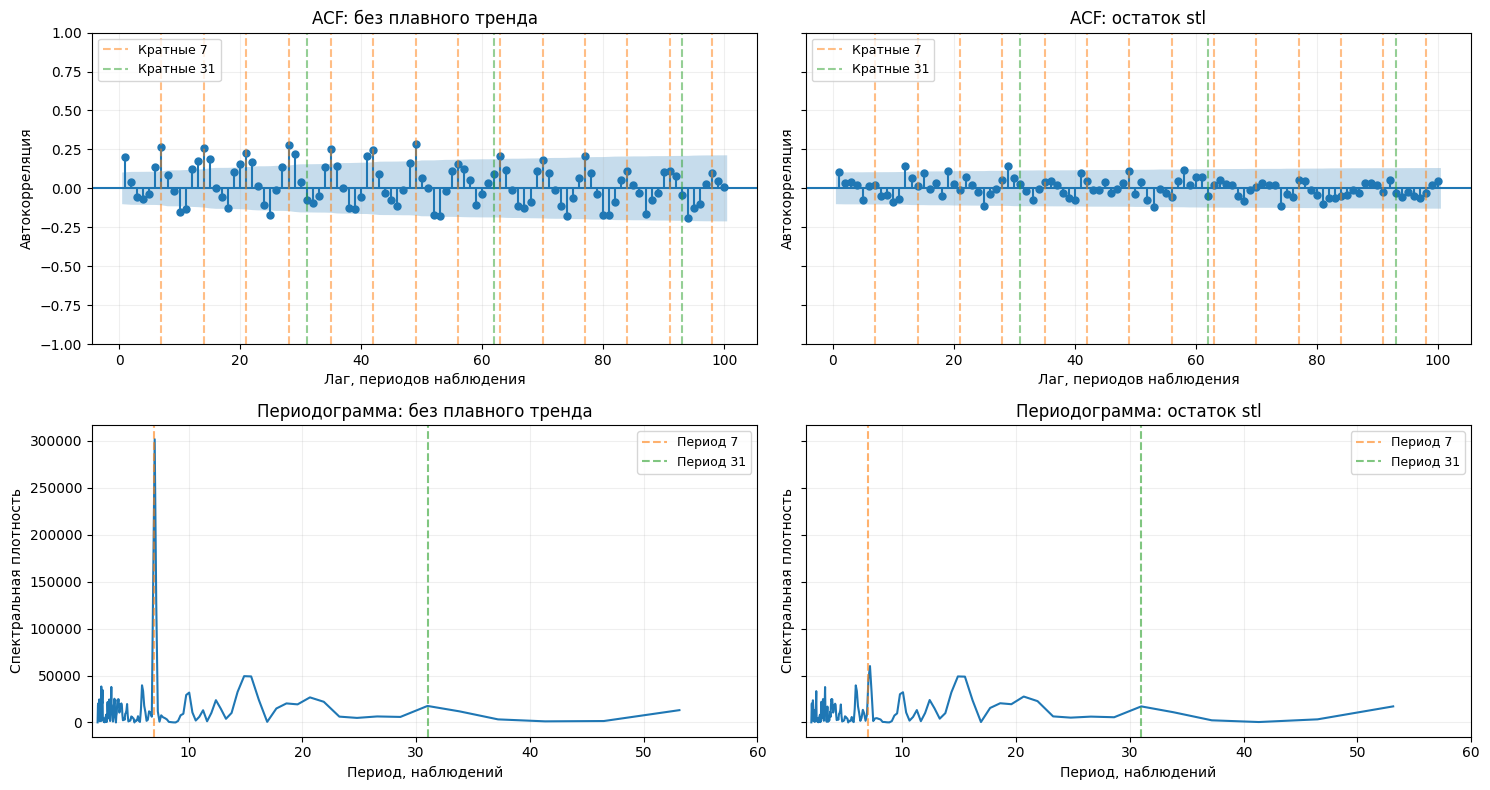

,Без плавного тренда,Остаток STL
Лаг,,
7,0.27,0.02
14,0.26,0.02
21,0.23,-0.01
28,0.28,0.06
31,-0.07,0.03
62,0.09,-0.05
93,-0.05,-0.03


Период пика  Спектральная плотность
Ряд                 Ранг                                     
Без плавного тренда 1            7.02               301609.41
                    2           14.88                49321.67
                    3            5.90                39585.62
                    4            2.32                38336.63
                    5            3.21                37831.66
Остаток STL         1            7.15                60056.82
                    2           14.88                49027.97
                    3            5.90                39513.04
                    4            3.21                37726.89
                    5            2.43                33357.24

In [61]:
seasonality_daily = check_seasonality(stl_daily, periods=(7, 31),
                                      max_lag=100, max_period=60)
display(seasonality_daily['acf'].round(2))
display(seasonality_daily['peaks'].round(2))

> Недельный цикл поддерживают оба графика. ACF на лагах, кратных 7, имеет пики, которые выходят за доверительный интервал, а главный спектральный пик соответствует периоду ~7 дней.
> В остатке STL связи на этих лагах заметно слабее, как и пик около недели на периодограмме. При этом слабый пик около 7 и другие колебания сохраняются, поэтому остаток еще нельзя считать белым шумом.
>
> На лагах, кратных 31, acf не показывает положительных пиков. Около 31 дня нет выраженного спектрального максимума. Эти графики не подтверждают предположение о наличии цыкла длиной 31 день. Периода такой длины нет и в топ-5 кандидатах по таблице.

### б) Агрегация по неделям

#### 1. Выберите подходящий метод декомпозиции. 

> Выберем аддитивный STL: он выделяет плавный тренд, допускает изменение сезонного рисунка и при `robust=True` уменьшает влияние отдельных всплесков. Период 4 недели рассматриваем как гипотезу коротких повторяющихся колебаний.
>
> Для сравнения посмотрим `seasonal_decompose` с неизменным сезонным рисунком и `decompose_harmonic` с плавным полиномиальным трендом. Гармоническая регрессия допускает дробные периоды: например, 4.5 недели соответствуют 31.5 дня. Устойчивость рассматриваемых циклов проверим отдельно по ACF и периодограмме.

#### 2. Разложите временной ряд на компоненты, предусмотренные выбранным методом. 

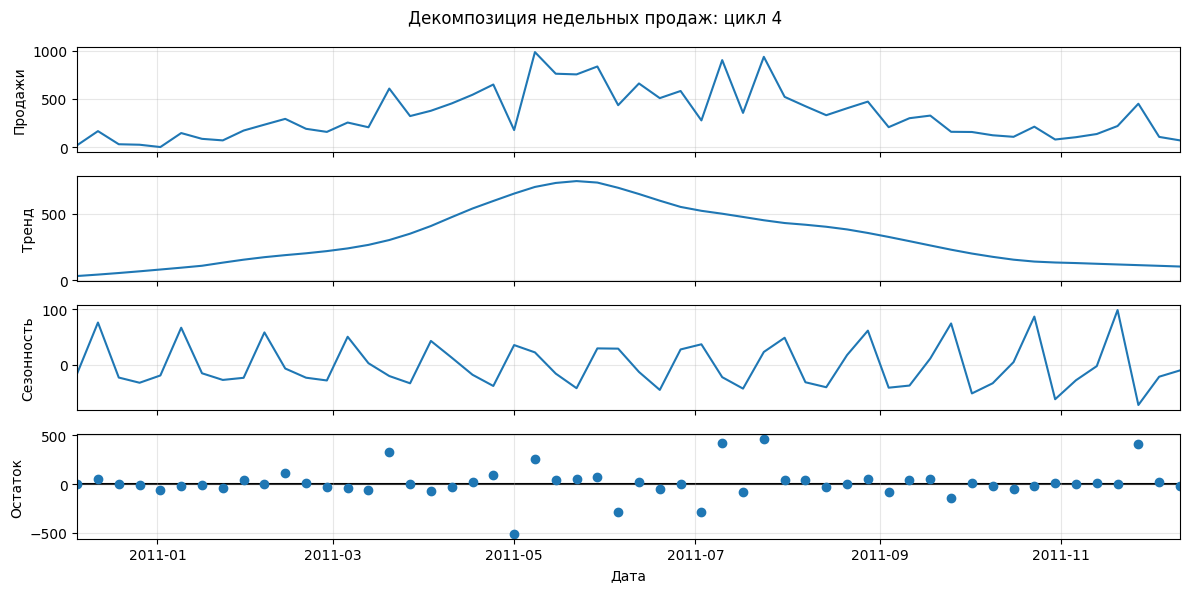

In [62]:
stl_weekly = decompose_sales_stl(
    sales_weekly,
    period=4,
    seasonal=13,
    trend=13,
    title='Декомпозиция недельных продаж: цикл 4'
)

> Тренд показывает рост продаж до мая и последующее снижение. Амплитуда сезонной компоненты меняется (к концу наблюдений колебания выражены сильнее). Всплески и провалы остаются в остатке, поэтому тренд и предполагаемый цикл объясняют только часть изменений продаж.

> Еще попробуем график через `seasonal_decompose`. Он хорошо работает, если сезонный рисунок практически не меняется.

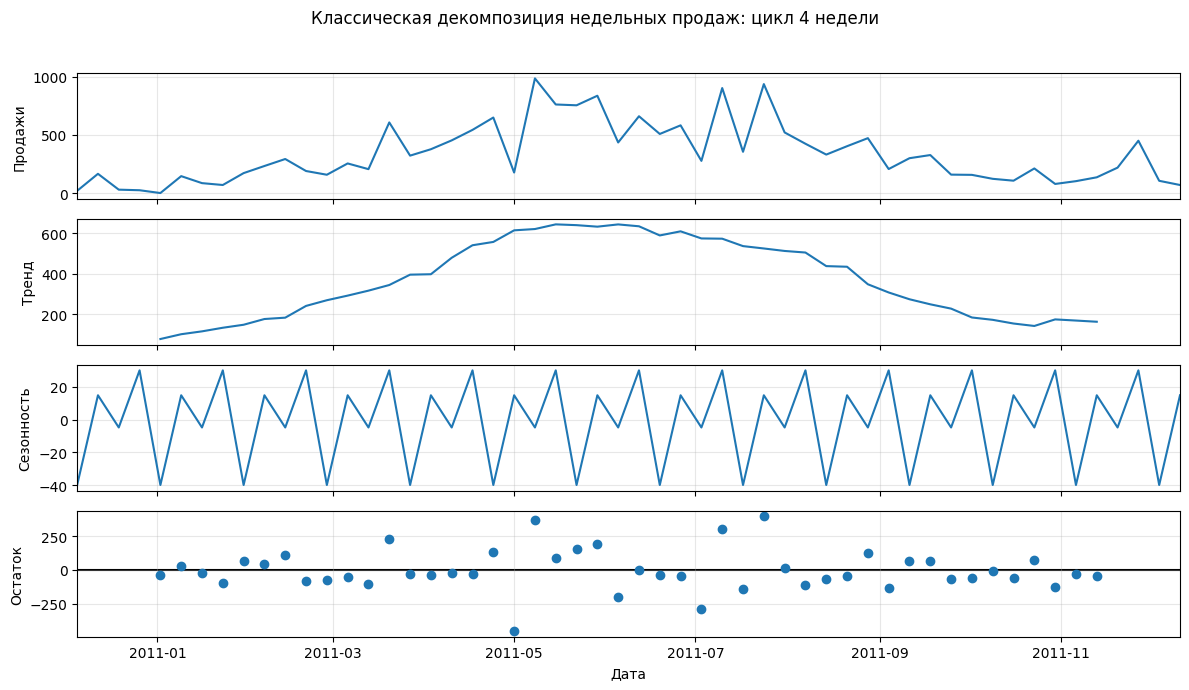

In [63]:
classical_weekly_4 = decompose_sales_classical(
    sales_weekly, period=4, filt=np.ones(9) / 9,
    title='Классическая декомпозиция недельных продаж: цикл 4 недели'
)

> Сезонный рисунок одинаково повторяется каждые четыре недели, но его амплитуда невелика относительно общего разброса продаж. В остатке сохраняются значительные отклонения.

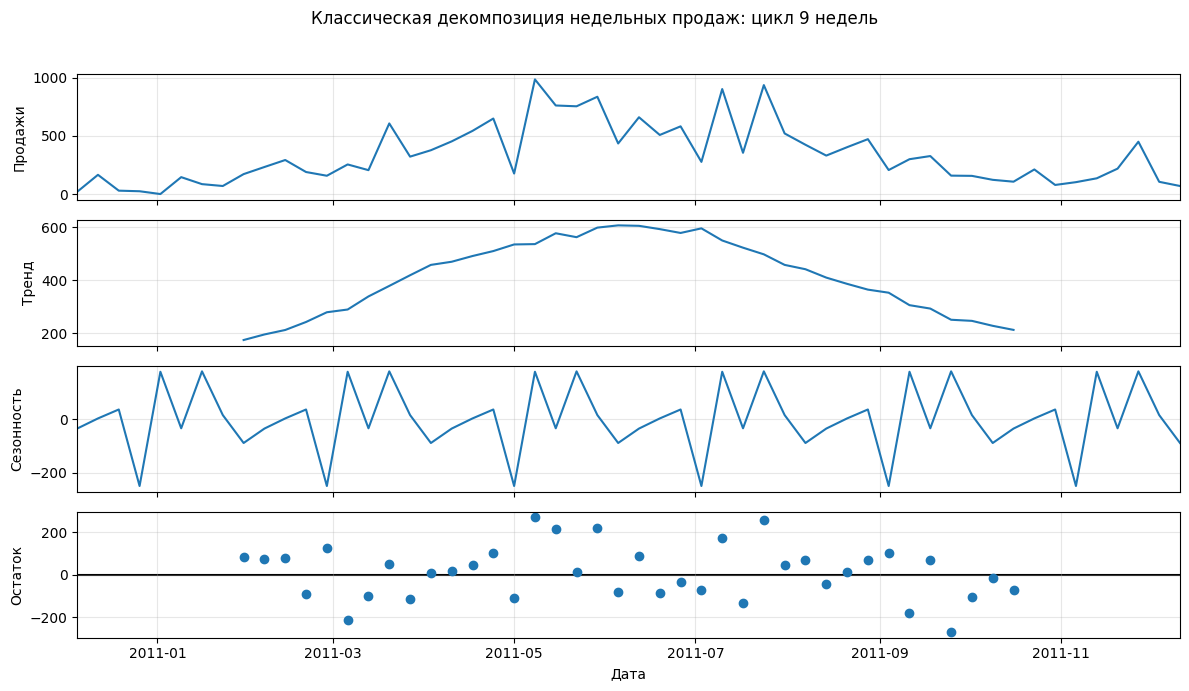

In [64]:
classical_weekly_9 = decompose_sales_classical(
    sales_weekly, period=9, filt=np.ones(17) / 17,
    title='Классическая декомпозиция недельных продаж: цикл 9 недель'
)

> Для цикла в 9 недель видим повторяющийся сезонный рисунок и достаточно гладкий тренд.

In [65]:
from statsmodels.tsa.seasonal import DecomposeResult

def decompose_harmonic(y, period=None, degree=4):
    t = np.arange(len(y))
    z = np.linspace(-1, 1, len(y))

    trend_features = np.column_stack([z**k for k in range(degree + 1)])
    seasonal_features = (
        np.column_stack([
            np.sin(2 * np.pi * t / period),
            np.cos(2 * np.pi * t / period)
        ])
        if period is not None else np.empty((len(y), 0))
    )

    x = np.column_stack([trend_features, seasonal_features])
    coef = np.linalg.lstsq(x, y.to_numpy(), rcond=None)[0]

    trend = pd.Series(
        trend_features @ coef[:degree + 1], index=y.index, name='Тренд'
    )
    seasonal = pd.Series(
        seasonal_features @ coef[degree + 1:], index=y.index, name='Сезонность'
    )
    residual = (y - trend - seasonal).rename('Остаток')

    return DecomposeResult(y.rename('Продажи'), seasonal, trend, residual)

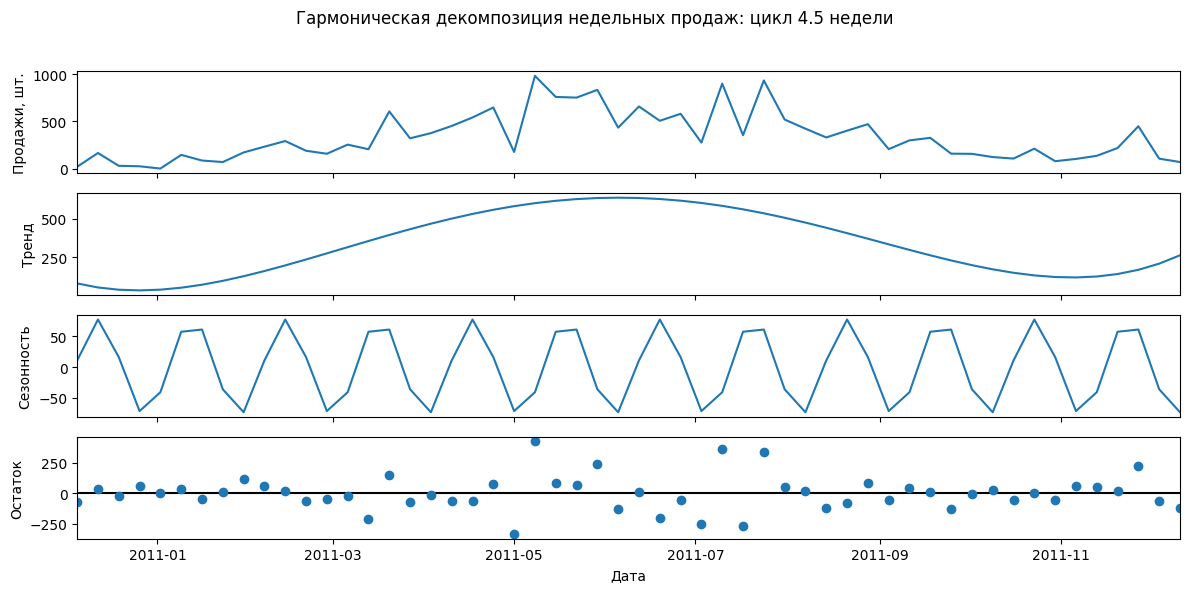

In [66]:
y_weekly = sales_weekly.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']

harmonic_weekly = decompose_harmonic(y_weekly, period=4.5, degree=4)
plot_decomposition(
    harmonic_weekly,
    'Гармоническая декомпозиция недельных продаж: цикл 4.5 недели'
)

> Полиномиальный тренд плавно описывает подъем продаж к маю–июню и дальнейший спад. Рост на краях краю может быть особенностью аппроксимации, поэтому не считаем их уверенным увеличением количества продаж. Сезонная компонента описывает заданный цикл около 4.5 недель (~месяц), но крупные отклонения все еще остаются в остатке.

#### 3. Проанализируйте тренд, сезонную и остаточную составляющие, если они выделяются используемым методом.

> Тренд. Как и в агрегации по дням, видим уверенный горб количества продаж в мае-июне. Эта динамика видна во всех разложениях, хотя форма тренда различается.
>
> Сезонность. выделенные колебания имеют небольшую амплитуду относительно общего разброса продаж. В STL сезонный рисунок постепенно меняется, а в остальных методах повторяется без изменений. Есть основания полагать наличие циклов длины 4, 4.5, 9 недель.
>
> Остаток. Cохраняются крупные отклонения, поэтому плавный тренд и выбранная сезонная компонента объясняют лишь часть изменений продаж. Возможно, остаточные всплески свидетельствуют о выбросах.

#### 4. Сделайте вывод о наличии или отсутствии выраженной сезонности.

Если сезонность предполагается, укажите ее предполагаемый период и обоснуйте вывод результатами 
анализа. 

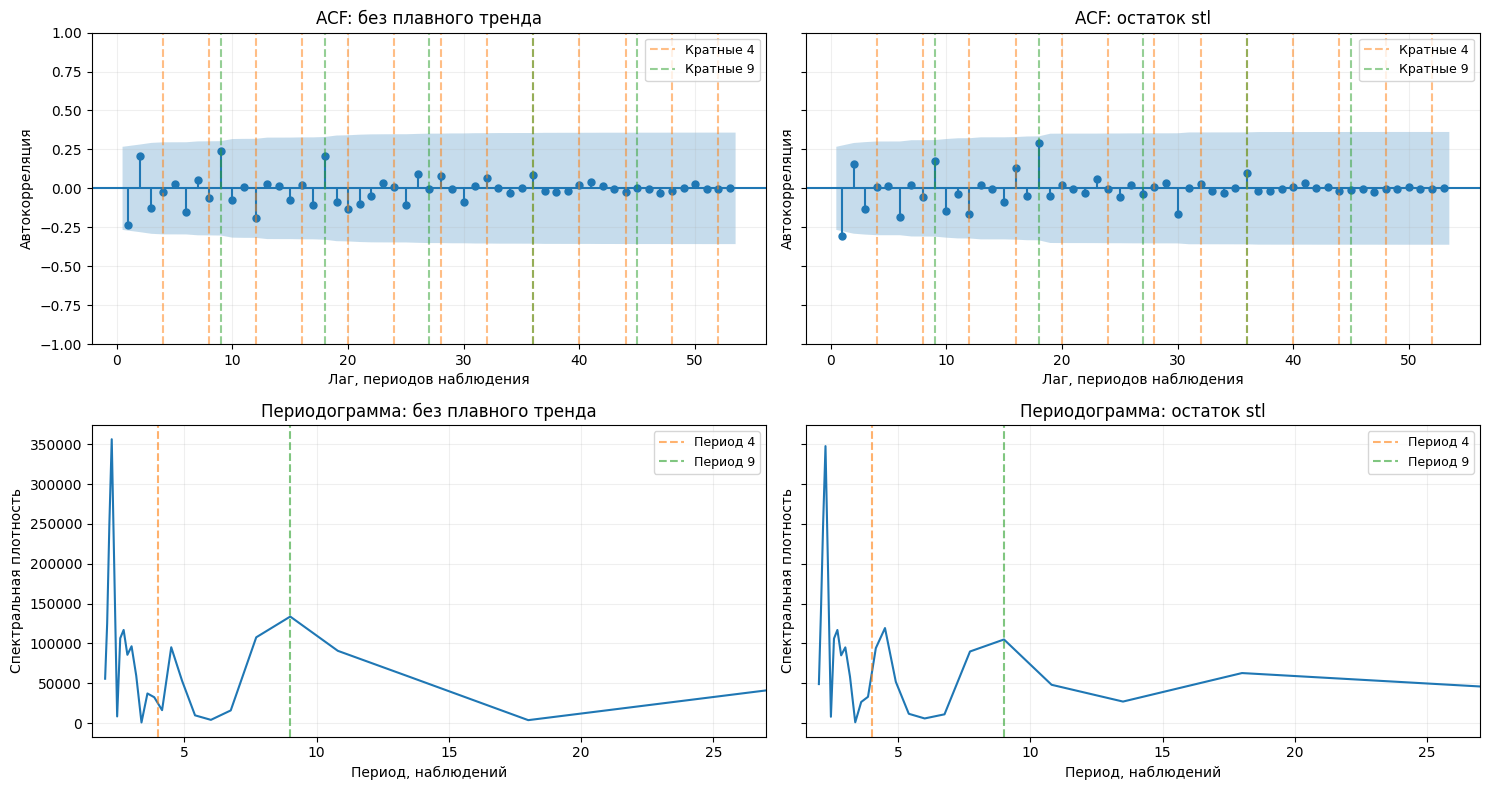

,Без плавного тренда,Остаток STL
Лаг,,
4,-0.02,0.01
8,-0.06,-0.06
9,0.24,0.17
12,-0.19,-0.16
16,0.02,0.13
18,0.21,0.29
27,-0.00,-0.04
36,0.08,0.10


Период пика  Спектральная плотность
Ряд                 Ранг                                     
Без плавного тренда 1            2.25               356183.08
                    2            9.00               133759.65
                    3            2.70               116966.52
                    4            3.00                96491.82
                    5            4.50                95273.79
Остаток STL         1            2.25               347544.27
                    2            4.50               119344.03
                    3            2.70               116927.23
                    4            9.00               105013.82
                    5            3.00                95113.49

In [67]:
seasonality_weekly = check_seasonality(stl_weekly, periods=(4, 9),
                                      max_lag=100, max_period=60)
display(seasonality_weekly['acf'].round(2))
display(seasonality_weekly['peaks'].round(2))

> Цикл длины 4 не подтверждается, но есть признаки цикла около 9 недель (~2 месяца). Для него есть пик на периодограмме. ACF на кратных 9 лагах выделяет пики, но они остаются внутри доверительных границ. Амплитуда на графике уменьшается со временем. 
>
> Наиболее сильный спектральный пик соответствует периоду около 2.25 недель, еще выделяется пик около 4.5 недель (~месяц). Наличие этих пиков не доказывает устойчивую сезонность, и могут быть побочными при наличии более уверенных циклов длины 9.

### в) Агрегация по месяцам

#### 1. Выберите подходящий метод декомпозиции. 

> В месячном ряду всего 13 наблюдений, поэтому делать выводы о сезонности будет сложно, и стоит сконцентрироваться на общем тренде. Выберем аддитивный STL: сглаживание помогает выделить эту динамику.
>
> Сравним результат с `seasonal_decompose`, предполагающим неизменный сезонный рисунок, и `decompose_harmonic`, который описывает тренд полиномом и допускает дробный период. Это позволит оценить, какие особенности тренда сохраняются при разных способах разложения. 

#### 2. Разложите временной ряд на компоненты, предусмотренные выбранным методом. 

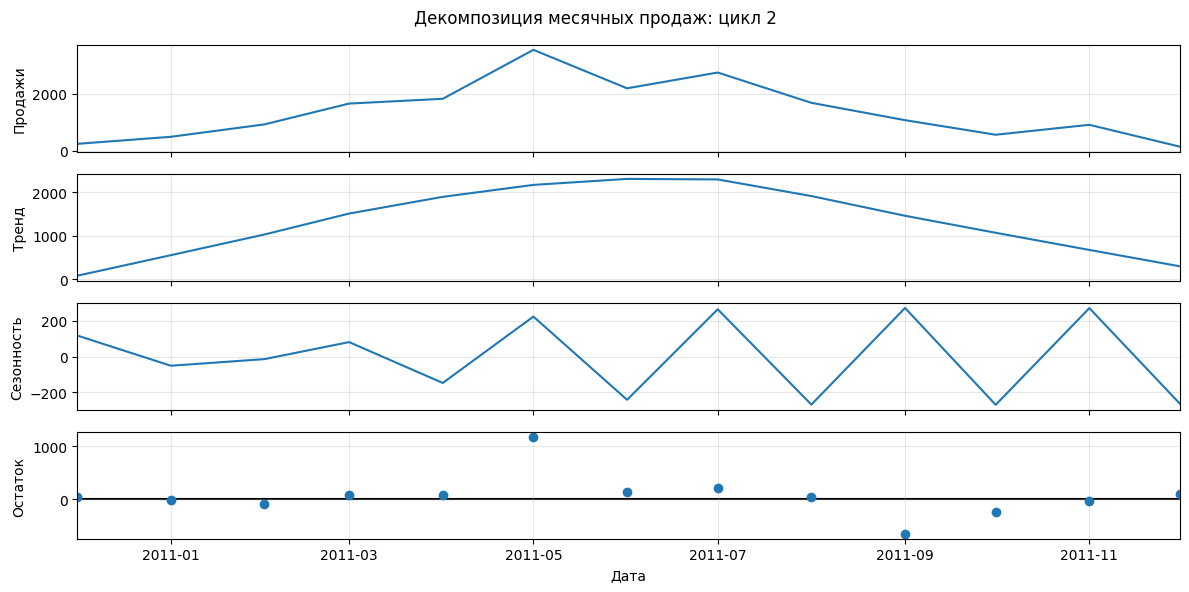

In [68]:
stl_monthly = decompose_sales_stl(
    sales_monthly,
    period=2,
    seasonal=7,
    trend=7,
    title=f'Декомпозиция месячных продаж: цикл 2'
)

> Раньше на графикаж видели глобальный максимум в мае-июне, на этом графике получили его ближе к июлю. Сезонная компонента задает чередование месяцов. Майский всплеск и сентябрьский провал остаются в остатке.

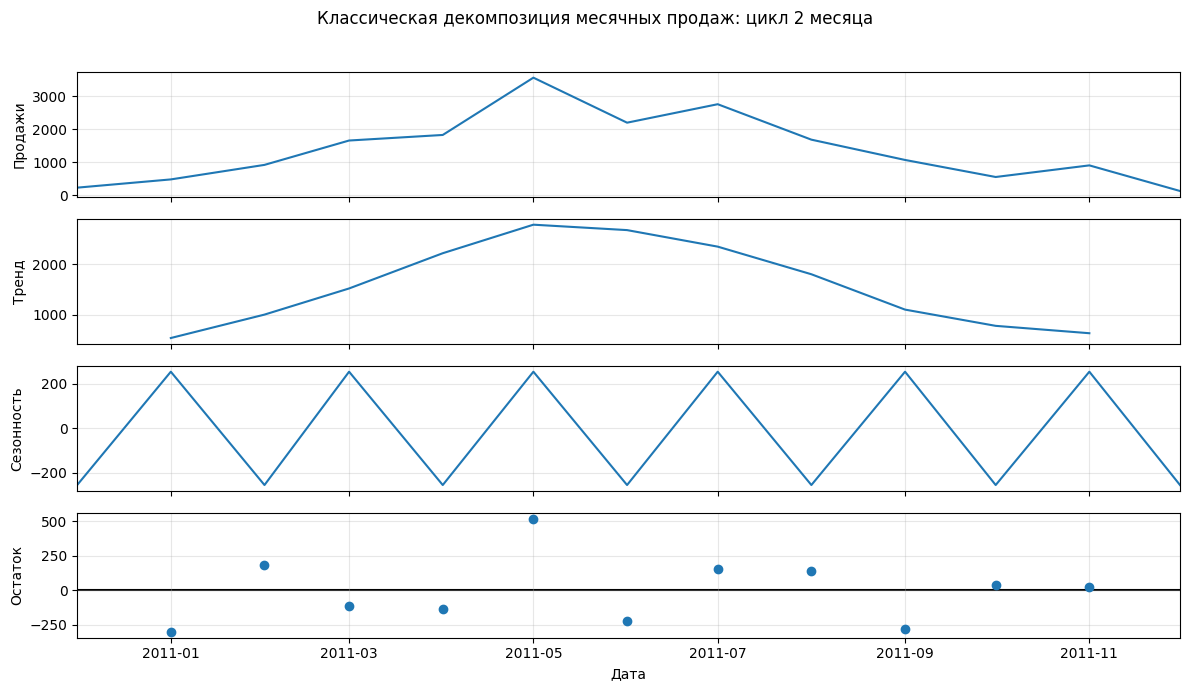

In [69]:
classical_monthly = decompose_sales_classical(
    sales_monthly, period=2,
    title='Классическая декомпозиция месячных продаж: цикл 2 месяца'
)

> В этом разложении максимум тренда приходится на май. Сезонный рисунок повторяется каждые два месяца с одинаковой амплитудой. Колебание остатков сохраняется.

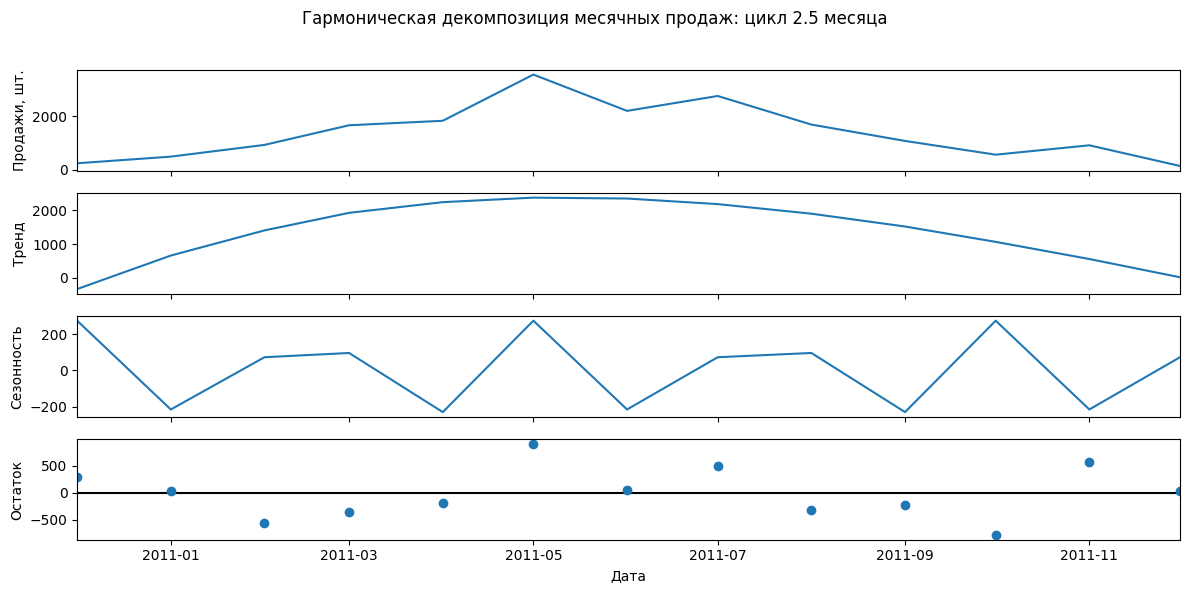

In [70]:
y_monthly = sales_monthly.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']

harmonic_monthly = decompose_harmonic(y_monthly, period=2.5, degree=3)
plot_decomposition(
    harmonic_monthly,
    'Гармоническая декомпозиция месячных продаж: цикл 2.5 месяца'
)

> Гармоническое разложение здесь выглядит менее удачным. Короткий ряд затрудняет оценку компонентов

#### 3. Проанализируйте тренд, сезонную и остаточную составляющие, если они выделяются используемым методом.

> Тренд. Во всех разложениях видны рост продаж к маю-июню и последующее снижение. Точное положение максимума и форма тренда зависят от метода сглаживания.
>
> Сезонность. Выделенные колебания имеют меньшую амплитуду, чем общее изменение уровня продаж. В STL сезонный рисунок меняется, а в классическом и гармоническом разложениях задается повторяющаяся форма. Период длины 2 - кандидат для дальнейшей проверки.
>
> Остаток. Майский всплеск и сентябрьский провал сохраняются во всех разложениях.

#### 4. Сделайте вывод о наличии или отсутствии выраженной сезонности.

Если сезонность предполагается, укажите ее предполагаемый период и обоснуйте вывод результатами 
анализа.

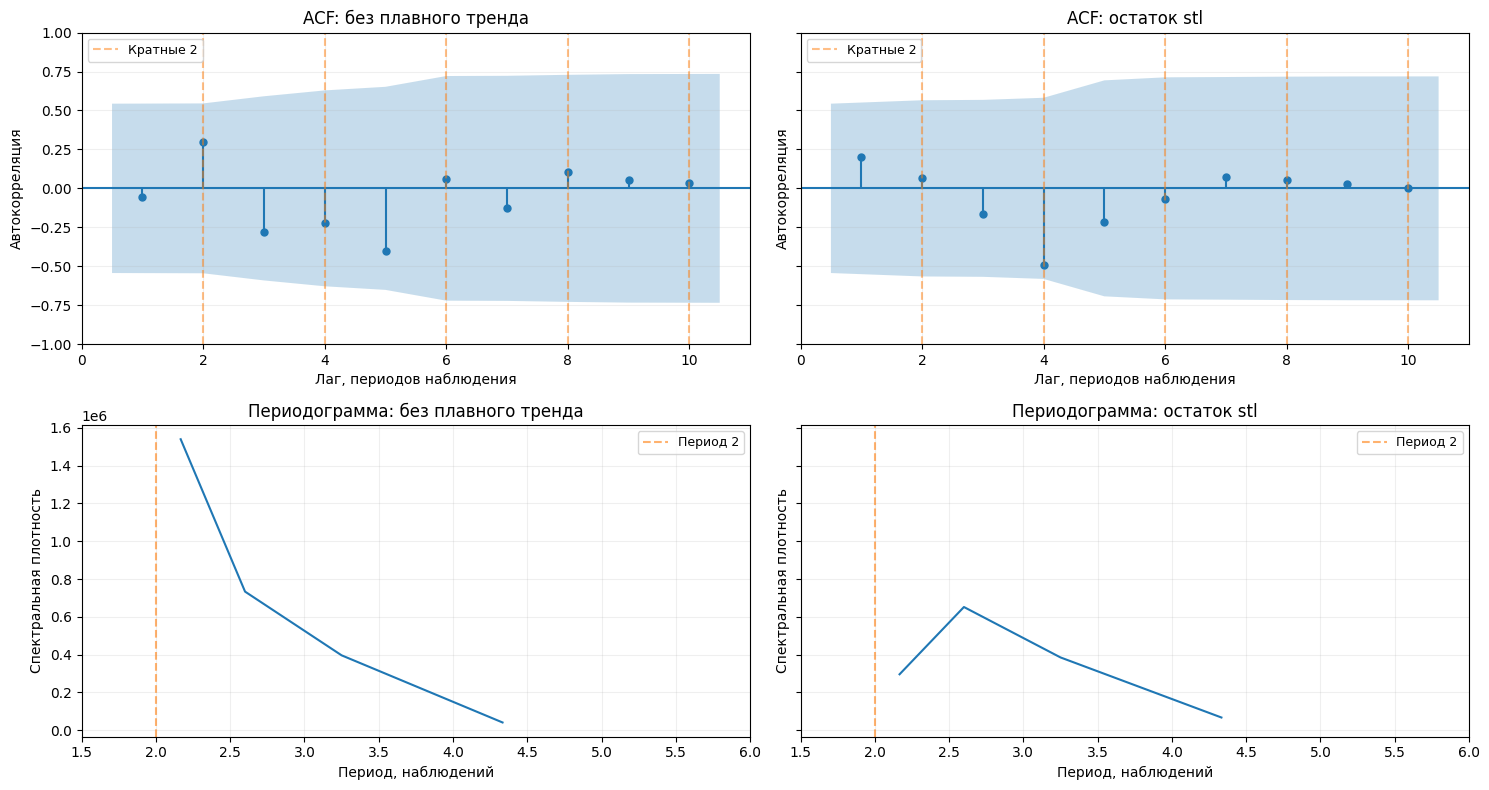

,Без плавного тренда,Остаток STL
Лаг,,
2,0.30,0.07
4,-0.22,-0.49
6,0.06,-0.07
8,0.11,0.05


,,Период пика,Спектральная плотность
Ряд,Ранг,,
Без плавного тренда,1,2.17,1540333.95
Остаток STL,1,2.60,651613.03


In [71]:
# Проверяем цикл около двух месяцев на коротком месячном ряду.
seasonality_monthly = check_seasonality(
    stl_monthly, periods=(2,), max_lag=10, max_period=6, trend_frac=0.6
)
display(seasonality_monthly['acf'].round(2))
display(seasonality_monthly['peaks'].round(2))

> В ряду всего 13 наблюдений, включая неполный декабрь 2011 года. Это затрудняет анализ сезонности.
>
> В целдом выраженная сезонность по месяцам не нешлась. На периодограмме выделяется пик около 2.17 месяца, но ACF на всем периоде внутри доверительных границ.

## Шаг 5. Проверьте стационарность

### Общее

> Исходными считаем `sales_daily`, `sales_weekly` и `sales_monthly` после обработки пропусков, но до преобразований для стационарности.

> Для слабой стационарности ряда нужны постоянные среднее, дисперсия, и структура автокорреляции. Последнее уже видели на графиках на прошлом шаге, поэтому достаточно проверить среднее и разброс.


>
> Для проверки стацонарности используем два теста при уровне значимости $\alpha=0.05$:
> - ADF: $H_0$ — в ряду есть единичный корень.
> - KPSS: $H_0$ — ряд стационарен относительно постоянного уровня (`regression='c'`).
>
> Дополняем тесты анализом скользящих среднего и стандартного отклонения. Стационарность требует постоянства среднего и дисперсии, а ковариация должна зависеть только от лага. ADF и KPSS не проверяют все эти свойства одновременно.

> Интерпретацию результатов по результатам тестов разбирали на лекции:
>
> 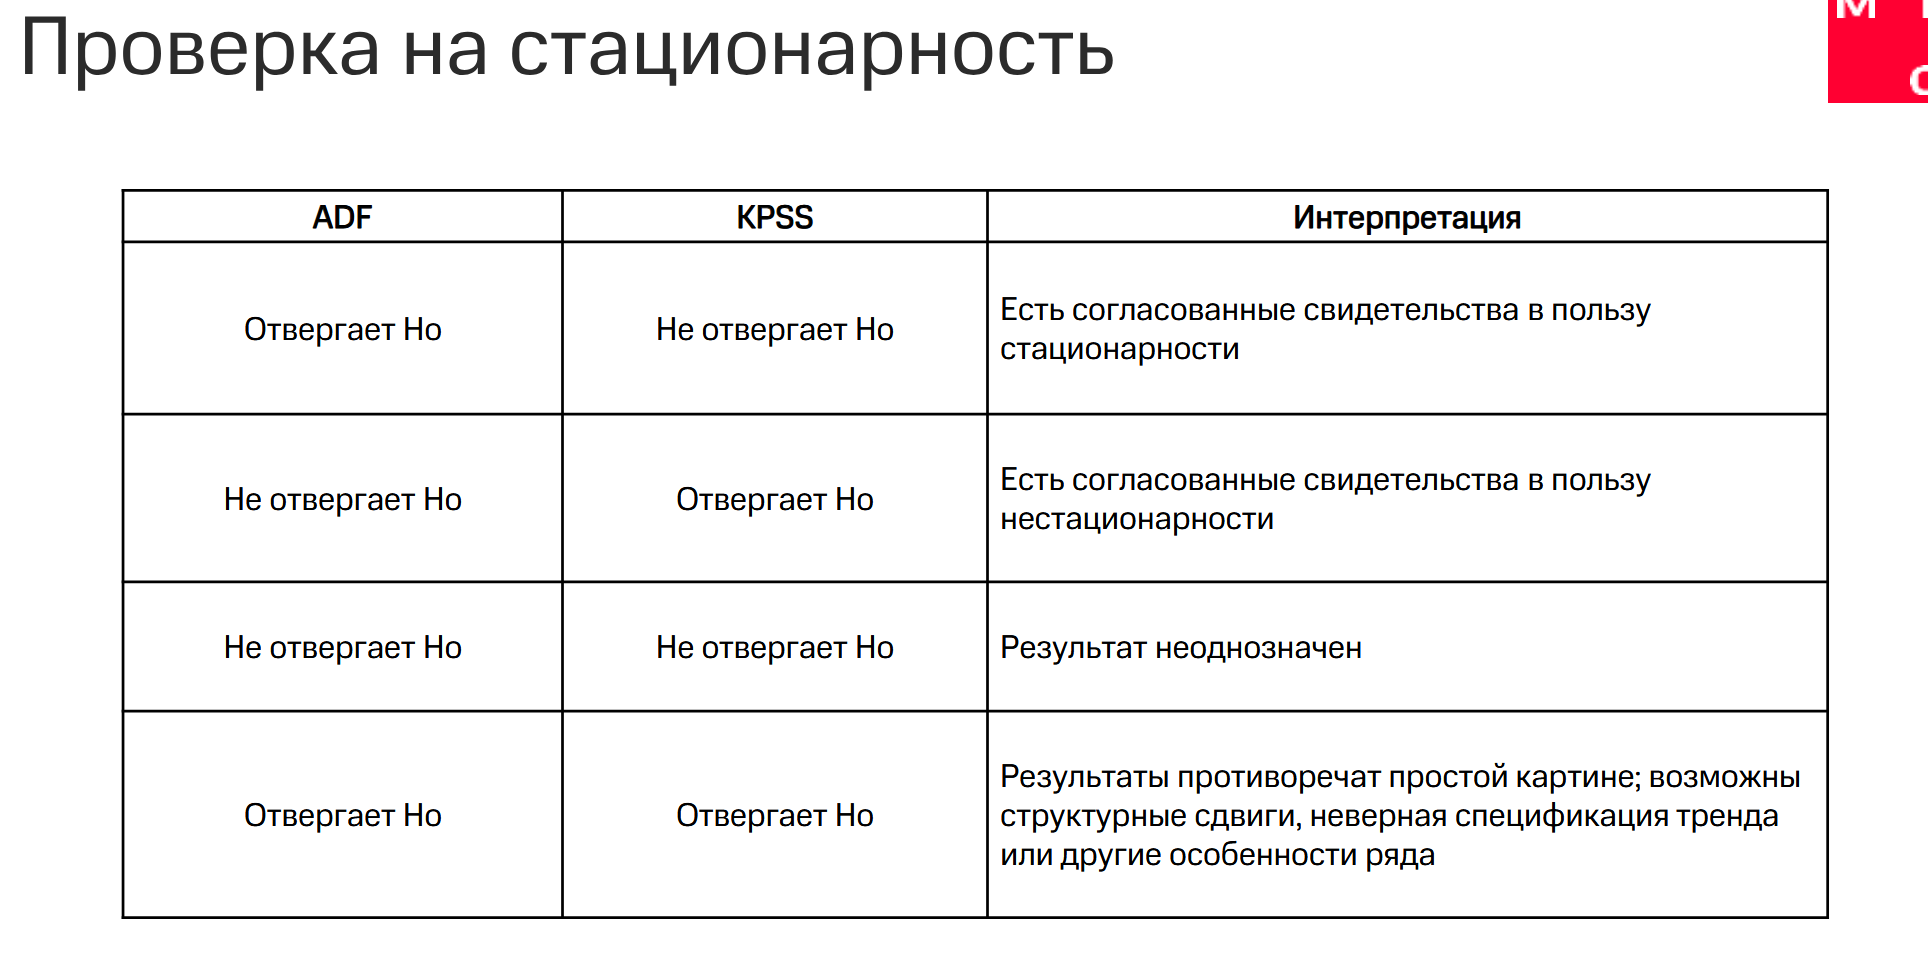
>
> Сочетание p ADF $\leq \alpha$ и p KPSS $> \alpha$ дает результаты в пользу стационарности. Если оба знака наоборот — в пользу нестационарности. Другие комбинации неоднозначны. Неотклонение гипотезы не доказывает ее истинность.

In [72]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning


def check_stationarity(y=None, df=None, max_lag=None, alpha=0.05,
                       regression='c', kpss_lags='auto'):
    if y is None:
        y = df.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']

    adf_result = adfuller(y, maxlag=max_lag, regression=regression,
                         autolag='AIC', result_object=False)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        kpss_result = kpss(y, regression=regression, nlags=kpss_lags,
                           result_object=False)

    adf_p, kpss_p = adf_result[1], kpss_result[1]
    kpss_p_text = ('<= 0.01' if kpss_p <= 0.01 else
                   '>= 0.10' if kpss_p >= 0.10 else f'{kpss_p:.3f}')
    if adf_p <= alpha and kpss_p > alpha:
        conclusion = 'В пользу стационарности'
    elif adf_p > alpha and kpss_p <= alpha:
        conclusion = 'В пользу нестационарности'
    elif adf_p <= alpha and kpss_p <= alpha:
        conclusion = 'Противоречие'
    else:
        conclusion = 'Неоднозначно'
    if regression == 'ct':
        conclusion += ' (относительно тренда)'

    return pd.Series({
        'n': len(y),
        'ADF': round(adf_result[0], 3),
        'p ADF': f'{adf_p:.3g}',
        'Лаг ADF': adf_result[2],
        'KPSS': round(kpss_result[0], 3),
        'p KPSS': kpss_p_text,
        'Лаг KPSS': kpss_result[2],
        'Вывод тестов': conclusion
    })


def compare_stationarity(df, transformations=None, window=7, max_lag=None,
                         alpha=0.05, plot=None, title=None, lag=1,
                         regression='c', kpss_lags='auto'):
    y = df.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity'].astype(float)

    if transformations is None:
        transformations = {f'Разности с лагом {lag}': lambda y: y.diff(lag)}

    series = {'Исходный ряд': y}
    for name, transform in transformations.items():
        z = transform(y.copy())
        if not isinstance(z, pd.Series) or not z.index.equals(y.index):
            raise ValueError(f'{name}: преобразование должно сохранять индекс ряда')
        valid = np.flatnonzero(z.notna())
        if not len(valid):
            raise ValueError(f'{name}: после преобразования не осталось значений')
        z = z.iloc[valid[0]:valid[-1] + 1]
        if not np.isfinite(z).all():
            raise ValueError(f'{name}: есть внутренние пропуски или бесконечности')
        series[name] = z

    results = pd.DataFrame({
        name: check_stationarity(y=z, max_lag=max_lag, alpha=alpha,
                                 regression=regression, kpss_lags=kpss_lags)
        for name, z in series.items()
    }).T
    variants = {
        name: z.rename('Quantity').rename_axis('InvoiceDate').reset_index()
        for name, z in series.items()
    }
    display(results)
    if plot is not None:
        plot_rolling_stats(variants[plot], window=window, title=title or plot,
                           ylabel='Значение ряда', label=plot)
    return variants, results

In [73]:
from scipy.stats import boxcox
from statsmodels.tsa.seasonal import seasonal_decompose


def signed_log(y):
    """Аналог log1p, сохраняющий нули и знак возвратов."""
    return np.sign(y) * np.log1p(y.abs())


def remove_seasonality(y, periods=(7,)):
    mstl = MSTL(y, periods=periods).fit()
    seasonal = mstl.seasonal
    if len(seasonal.shape) > 1 and seasonal.shape[1] > 1:
        seasonal = seasonal.sum(axis=1)
    return y-seasonal


def transform_boxcox(y):
    shift = max(0, 1 - y.min())
    values, lmbda = boxcox(y + shift)
    return pd.Series(values, index=y.index, name=y.name)


def detrend(y, periods=(7,)):
    mstl = MSTL(y, periods=periods).fit()
    return pd.Series(y-mstl.trend, index=y.index, name=y.name)

### а) Агрегация по дням

> На шаге 3 показали, что уровень и разброс дневных продаж меняются во времени. Сначала проверим исходный ряд:

In [74]:
pd.DataFrame(check_stationarity(df=sales_daily)).T

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
0,372,-2.015,0.28,14,0.859,<= 0.01,6,В пользу нестационарности


> При $\alpha=0.05$ ADF не отвергает единичный корень ($p \approx 0.28$), а KPSS отвергает стационарность относительно постоянного уровня ($p \leq 0.01$). Вместе с изменениями уровня и разброса на графиках это указывает на нестационарность исходного ряда. Поэтому преобразование требуется.

> Сравним несколько преобразований:

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
Исходный ряд,372,-2.015,0.28,14,0.859,<= 0.01,6,В пользу нестационарности
Логарифм,372,-3.04,0.0313,13,0.681,0.015,3,Противоречие
Разность с лагом 7,365,-8.477,1.42e-13,13,0.038,>= 0.10,6,В пользу стационарности
Удаление сезонности,372,-1.749,0.406,17,0.714,0.012,9,В пользу нестационарности
Удаление сезонности + diff(7),365,-9.329,9.44e-16,13,0.049,>= 0.10,5,В пользу стационарности
Бокс-Кокс,372,-2.296,0.173,14,0.793,<= 0.01,6,В пользу нестационарности
Детрендирование,372,-9.4,6.22e-16,17,0.025,>= 0.10,16,В пользу стационарности


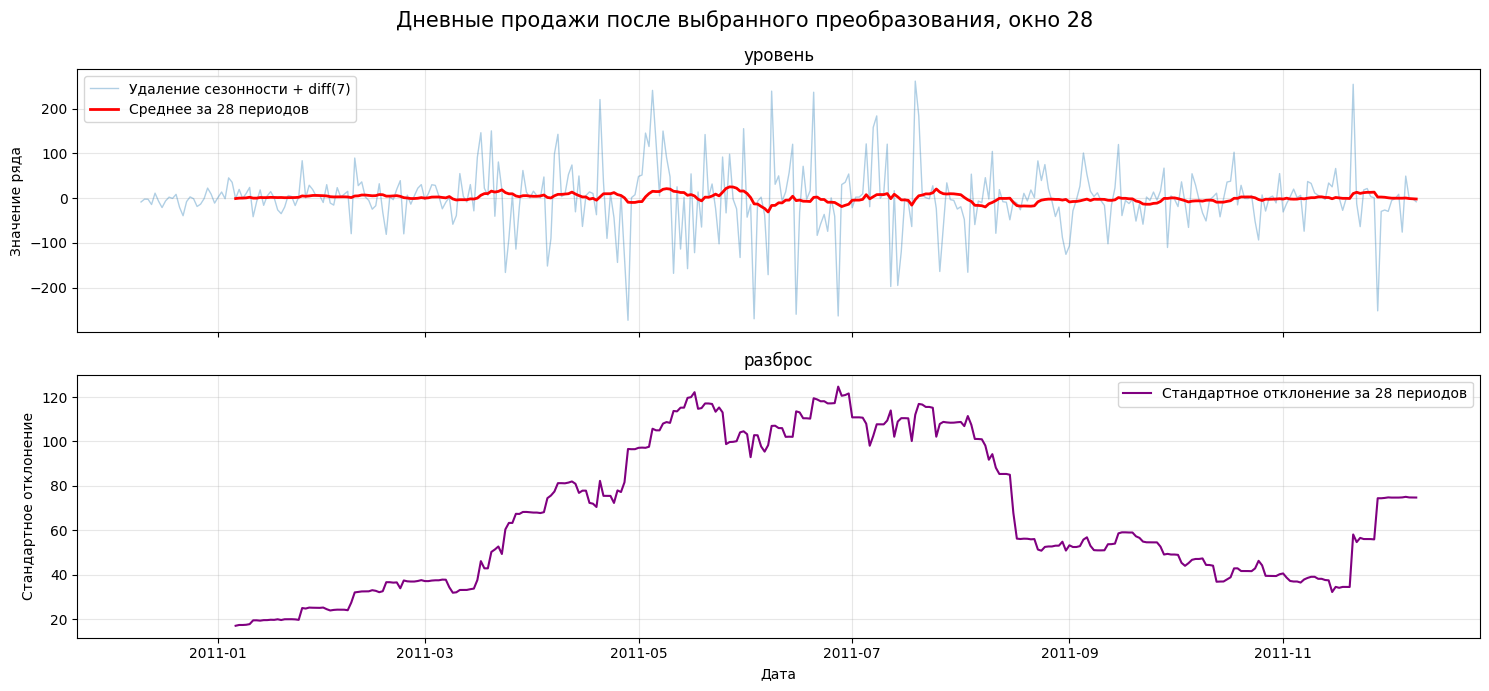

In [75]:
chosen_daily = 'Удаление сезонности + diff(7)'

daily_variants, stationarity_daily = compare_stationarity(
    sales_daily,
    transformations={
        'Логарифм': lambda y: signed_log(y),
        'Разность с лагом 7': lambda y: y.diff(7),
        'Удаление сезонности': lambda y: remove_seasonality(y, (7, 14,)),
        'Удаление сезонности + diff(7)': lambda y: remove_seasonality(y, (7, 14,)).diff(7),
        'Бокс-Кокс': transform_boxcox,
        'Детрендирование':  lambda y: (detrend(y, (7, 14))),
    },
    window=28, plot=chosen_daily,
    title='Дневные продажи после выбранного преобразования'
)

sales_daily_diff = daily_variants[chosen_daily]
sales_daily_transformed = daily_variants[chosen_daily]

> Проверим разброс на 8 последовательных непересекающихся участках. Если ряд имеет постоянную дисперсию, то и в этих блоках она должна быть близка.

In [76]:
def check_spread_bootstrap(df, parts=8, block=7, n_boot=10000, seed=20261116):
    """Сравнить дисперсии участков с помощью кругового блочного бутстрэпа."""
    y = df.sort_values('InvoiceDate').set_index('InvoiceDate')['Quantity']
    values = y.to_numpy(dtype=float)
    n = len(values)
    if not np.isfinite(values).all():
        raise ValueError('Сначала обработайте пропуски и бесконечности')
    if not 2 <= parts <= n // 2 or not 1 <= block < n or n_boot < 1:
        raise ValueError('Проверьте число участков, длину блока и число повторов')

    groups = np.arange(n) * parts // n
    summary = y.groupby(groups).agg(
        start=lambda v: v.index.min(), end=lambda v: v.index.max(),
        n='size', mean='mean', std='std'
    )
    summary.index = pd.Index(range(1, parts + 1), name='Участок')

    def statistic(samples):
        variances = np.stack([
            samples[..., groups == group].var(axis=-1, ddof=1)
            for group in range(parts)
        ], axis=-1)
        low, high = variances.min(axis=-1), variances.max(axis=-1)
        ratio = np.divide(high, low, out=np.full_like(high, np.inf), where=low > 0)
        # Все дисперсии нулевые — различий нет; только часть нулевая — T бесконечна.
        return np.log(np.where(high == 0, 1, ratio))

    observed = statistic(values)
    rng = np.random.default_rng(seed)
    starts = rng.integers(n, size=(n_boot, int(np.ceil(n / block))))
    indices = (starts[:, :, None] + np.arange(block)) % n
    indices = indices.reshape(n_boot, -1)[:, :n]
    simulated = statistic(values[indices])
    p_value = (1 + np.sum(simulated >= observed)) / (n_boot + 1)
    return summary, float(p_value)

In [77]:
def analyse_spread(variants, transformed, parts=8, block=7, n_boot=10000, seed=20261116):
    spread = {}
    for name, df in variants.items():
        summary, p_time = check_spread_bootstrap(
            df, parts=parts, block=block, n_boot=n_boot, seed=seed
        )
        spread[name] = {
            'p бутстрэп: участки во времени': p_time,
            'Отношение max/min std участков': summary['std'].max() / summary['std'].min()
        }

    spread = pd.DataFrame(spread).T
    display(spread.style.format({
        'p бутстрэп: участки во времени': '{:.3g}',
        'Отношение max/min std участков': '{:.2f}'
    }))

    spread_selected, _ = check_spread_bootstrap(
        transformed, parts=parts, block=block, n_boot=n_boot, seed=seed
    )
    display(spread_selected.round(2))
    return spread, spread_selected

In [78]:
spread_parts_daily = 8
bootstrap_block_daily = 14
spread_daily, spread_daily_selected = analyse_spread(
    daily_variants, sales_daily_transformed,
    parts=spread_parts_daily, block=bootstrap_block_daily
)

,p бутстрэп: участки во времени,Отношение max/min std участков
Исходный ряд,0.0109,5.93
Логарифм,0.0175,1.89
Разность с лагом 7,0.0018,6.35
Удаление сезонности,0.002,5.73
Удаление сезонности + diff(7),0.0003,6.49
Бокс-Кокс,0.0075,4.82
Детрендирование,0.0057,6.25


,start,end,n,mean,std
Участок,,,,,
1,2010-12-10,2011-01-24,46,-1.95,17.60
2,2011-01-25,2011-03-11,46,3.42,35.36
3,2011-03-12,2011-04-25,45,6.85,79.20
4,2011-04-26,2011-06-10,46,1.68,114.24
5,2011-06-11,2011-07-26,46,1.44,111.15
6,2011-07-27,2011-09-09,45,-6.88,54.45
7,2011-09-10,2011-10-25,46,-5.37,44.95
8,2011-10-26,2011-12-09,45,-0.67,61.17


> Некоторые преобразования проходят ADF/KPSS, но проверка разброса для них отвергает равенство дисперсий. Поэтому ни одно из преобразований не дает стационарный ряд. 

### б) Агрегация по неделям

> На шаге 3 показали, что уровень и разброс продаж меняются во времени. Сначала проверим исходный ряд:

In [79]:
pd.DataFrame(check_stationarity(df=sales_weekly)).T

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
0,54,-1.788,0.387,1,0.276,>= 0.10,4,Неоднозначно


> Сравним несколько преобразований:

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
Исходный ряд,54,-1.788,0.387,1,0.276,>= 0.10,4,Неоднозначно
Логарифм,54,-2.193,0.209,1,0.333,>= 0.10,4,Неоднозначно
Разность с лагом 3,51,-1.463,0.552,7,0.305,>= 0.10,3,Неоднозначно
Удаление сезонности,54,-1.324,0.618,2,0.284,>= 0.10,4,Неоднозначно
Детрендирование,54,-4.835,4.66e-05,8,0.091,>= 0.10,9,В пользу стационарности
Бокс-Кокс,54,-1.748,0.407,1,0.305,>= 0.10,4,Неоднозначно
Разность + log,53,-10.809,1.93e-19,0,0.058,>= 0.10,1,В пользу стационарности


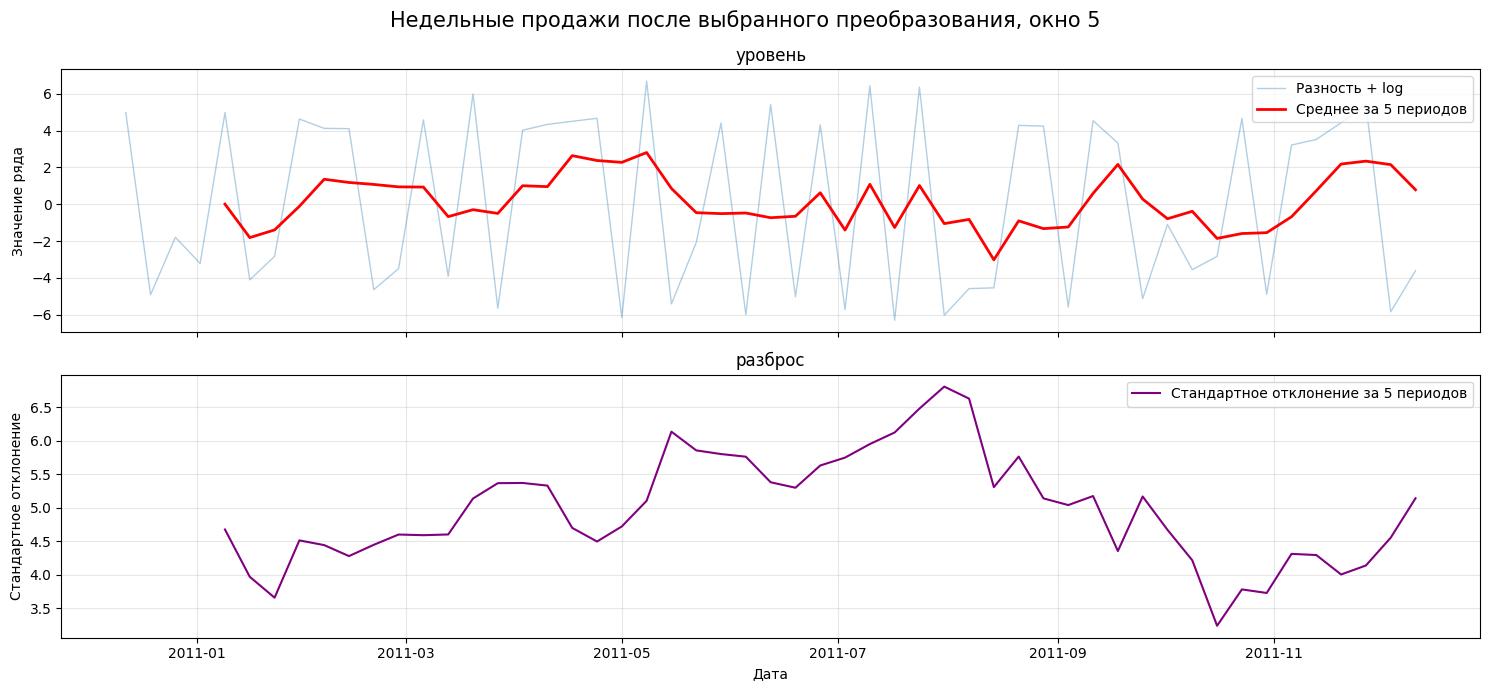

In [80]:
chosen_weekly = 'Разность + log'

weekly_variants, stationarity_weekly = compare_stationarity(
    sales_weekly,
    transformations={
        'Логарифм': lambda y: signed_log(y),
        'Разность с лагом 3': lambda y: y.diff(3),
        'Удаление сезонности': lambda y: remove_seasonality(y, (9,)),
        'Детрендирование':  lambda y: detrend(y, (3,)),
        'Бокс-Кокс': lambda y: transform_boxcox(y),
        'Разность + log': lambda y: signed_log(y.diff()),
    },
    window=5, plot=chosen_weekly,
    title='Недельные продажи после выбранного преобразования'
)

sales_weekly_diff = weekly_variants[chosen_weekly]
sales_weekly_transformed = weekly_variants[chosen_weekly]

> Проверим разброс

In [81]:
spread_parts_weekly = 3
bootstrap_block_weekly = 5
spread_weekly, spread_weekly_selected = analyse_spread(
    weekly_variants, sales_weekly_transformed,
    parts=spread_parts_weekly, block=bootstrap_block_weekly
)

,p бутстрэп: участки во времени,Отношение max/min std участков
Исходный ряд,0.375,1.78
Логарифм,0.101,3.34
Разность с лагом 3,0.0333,2.84
Удаление сезонности,0.842,1.21
Детрендирование,0.145,2.52
Бокс-Кокс,0.515,1.47
Разность + log,0.099,1.25


,start,end,n,mean,std
Участок,,,,,
1,2010-12-12,2011-04-10,18,0.4,4.46
2,2011-04-17,2011-08-14,18,-0.5,5.51
3,2011-08-21,2011-12-11,17,0.3,4.41


> Среди преобразований, которые проходят тесты ADF и KPSS, разброс меньше всего меняется у преобразования 'Разность + log'. На графике видно, что  среднее и разброс немного колеблются, и в целом преобразованный ряд можно считать приближенно стационарным.

### в) Агрегация по месяцам

> Сначала проверим исходный ряд:

In [82]:
pd.DataFrame(check_stationarity(df=sales_monthly)).T

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
0,13,-6.531,9.85e-09,4,0.188,>= 0.10,1,В пользу стационарности


> Сравним несколько преобразований:

,n,ADF,p ADF,Лаг ADF,KPSS,p KPSS,Лаг KPSS,Вывод тестов
Исходный ряд,13,-6.531,9.85e-09,4,0.188,>= 0.10,1,В пользу стационарности
Логарифм,13,-3.848,0.00245,4,0.206,>= 0.10,1,В пользу стационарности
Разность,12,-15.67,1.52e-28,4,0.308,>= 0.10,3,В пользу стационарности
Детрендирование,13,-3.344,0.013,4,0.256,>= 0.10,5,В пользу стационарности
Бокс-Кокс,13,-4.207,0.000641,2,0.309,>= 0.10,5,В пользу стационарности
Детрендирование + log,13,-7.508,4.09e-11,0,0.305,>= 0.10,6,В пользу стационарности


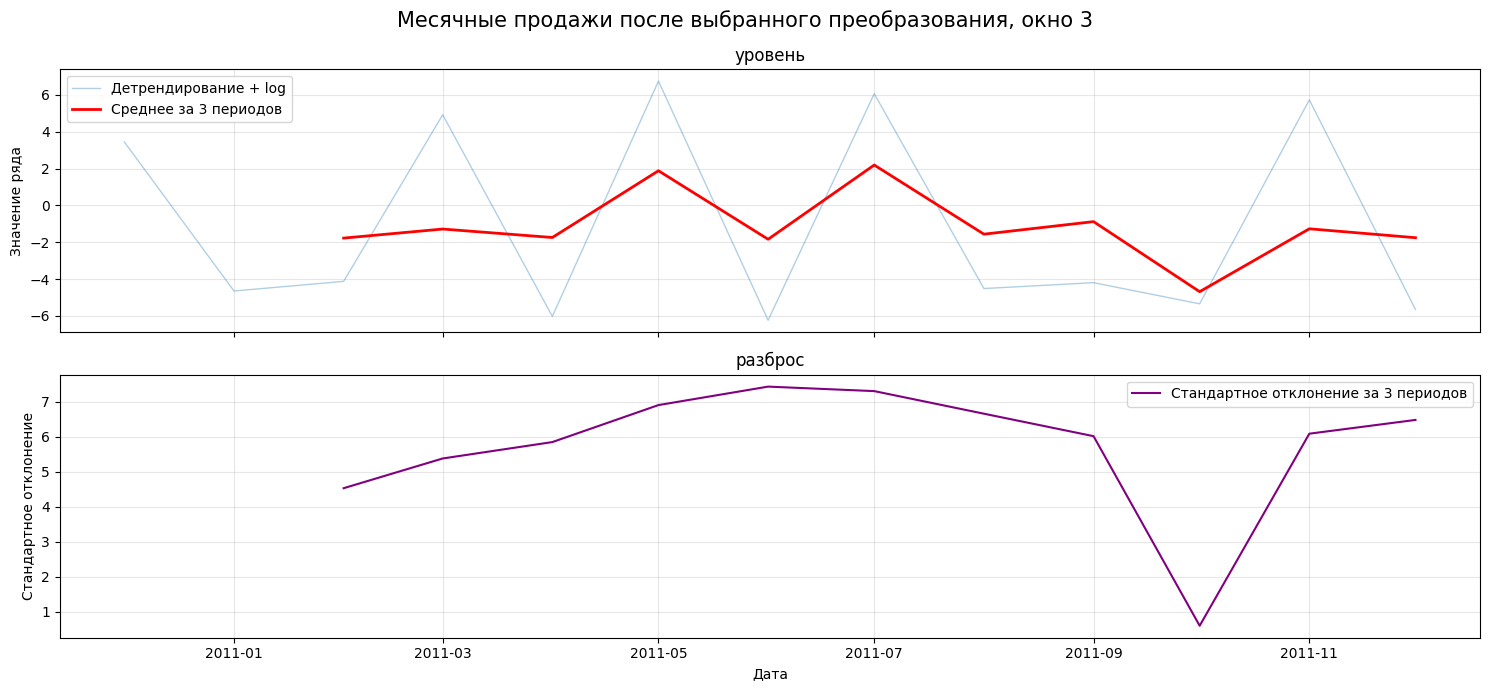

In [83]:
chosen_monthly = 'Детрендирование + log'
monthly_variants, stationarity_monthly = compare_stationarity(
    sales_monthly,
    transformations={
        'Логарифм': lambda y: signed_log(y),
        'Разность': lambda y: y.diff(),
        'Детрендирование':  lambda y: detrend(y, (2,)),
        'Бокс-Кокс': lambda y: transform_boxcox(detrend(y, (2,))),
        'Детрендирование + log': lambda y: signed_log(detrend(y, (2,))),
    },
    window=3, plot=chosen_monthly,
    title='Месячные продажи после выбранного преобразования'
)

sales_monthly_diff = monthly_variants[chosen_monthly]
sales_monthly_transformed = monthly_variants[chosen_monthly]

> Проверим разброс

In [84]:
spread_parts_monthly = 2
bootstrap_block_monthly = 3
spread_monthly, spread_monthly_selected = analyse_spread(
    monthly_variants, sales_monthly_transformed,
    parts=spread_parts_monthly, block=bootstrap_block_monthly
)

,p бутстрэп: участки во времени,Отношение max/min std участков
Исходный ряд,0.703,1.23
Логарифм,0.854,1.11
Разность,0.417,1.54
Детрендирование,0.497,1.55
Бокс-Кокс,0.394,1.80
Детрендирование + log,0.986,1.00


,start,end,n,mean,std
Участок,,,,,
1,2010-12-01,2011-06-01,7,-0.85,5.64
2,2011-07-01,2011-12-01,6,-1.32,5.62


In [85]:
spread_parts_monthly = 4
spread_monthly, spread_monthly_selected = analyse_spread(
    monthly_variants, sales_monthly_transformed,
    parts=spread_parts_monthly, block=bootstrap_block_monthly
)

,p бутстрэп: участки во времени,Отношение max/min std участков
Исходный ряд,0.784,2.35
Логарифм,0.644,2.86
Разность,0.136,6.30
Детрендирование,0.254,7.15
Бокс-Кокс,0.233,7.83
Детрендирование + log,0.504,1.49


,start,end,n,mean,std
Участок,,,,,
1,2010-12-01,2011-03-01,4,-0.10,4.99
2,2011-04-01,2011-06-01,3,-1.84,7.44
3,2011-07-01,2011-09-01,3,-0.88,6.02
4,2011-10-01,2011-12-01,3,-1.76,6.49


> Все преобразования проходят тесты ADF и KPSS, разброс близок к стационарному всегда - это вызвано тем, что ряд короткий совсем. После преобразования 'Детрендирование + log' получили стационарный ряд.
>
> Из-за короткого ряда и чувствительности к лагам окончательный вывод сделать нельзя.

## Шаг 7. Выводы

> Анализируем продажи товара `47566`, показатель - сумма `Quantity` с учетом возвратов. Пропуски обработаны отдельно для каждой агрегации, потенциальные выбросы и отрицательные значения сохранены. Уровень и разброс меняются во времени, с наиболее высокими продажами весной и летом 2011 года.
>
> На дневной частоте подтверждается недельный цикл. На недельной частоте есть цикл длины 4.5 недели. Для месячной частоты циклов не нашлось. 
>
> Все три агрегации дают нестационарные ряды. По дням неоднородность разброса остается после рассмотренных преобразований, этот ряд не удалось привести к стационарному виду. Ряд с недельной агрегацией удалось привести к стационарному. Анализ ряда по месяцам усложняется тем, что он короткий.